# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import os
import sys
import subprocess

try:
    import kagglehub
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

# Download latest version
path = kagglehub.dataset_download("zohairbaloch/netflix-titles-enriched-with-imdb-and-tmdb")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "netflix_content_intelligence_combined.csv"))

df.head()

100%|██████████| 1.57M/1.57M [00:01<00:00, 1.36MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/zohairbaloch/netflix-titles-enriched-with-imdb-and-tmdb/versions/1


,content_id,title,type,release_year,release_decade,release_year_group,content_age,date_added,rating,duration,...,primary_country,country_count,is_original,is_recent_release,has_rating,has_cast,has_director,data_completeness_score,match_method,match_confidence
0,nf_2879cda65363,3%,TV Show,2020,2020,2020-2022,6,"August 14, 2020",TV-MA,4 Seasons,...,Brazil,1,False,False,True,True,False,0.857,fuzzy_title_year,0.89
1,nf_73818ff7bd91,7:19,Movie,2016,2010,2016-2019,10,"December 23, 2016",TV-MA,93 min,...,Mexico,1,False,False,True,True,True,1.000,exact_title_year,0.90
2,nf_821496e58bca,23:59,Movie,2011,2010,2010-2015,15,"December 20, 2018",R,78 min,...,Singapore,1,False,False,True,True,True,1.000,exact_title_year,0.90
3,nf_be2013d8c4ac,9,Movie,2009,2000,2000s,17,"November 16, 2017",PG-13,80 min,...,United States,1,False,False,True,True,True,1.000,exact_title_year,0.90
4,nf_f4e65f8e18a8,21,Movie,2008,2000,2000s,18,"January 1, 2020",PG-13,123 min,...,United States,1,False,False,True,True,True,1.000,exact_title_year,0.90


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** Nesta atividade, realizamos uma Análise Exploratória de Dados (EDA) aplicada ao dataset Netflix Intelligence. Esta análise foca em um domínio de entretenimento e streaming, explorando metadados sobre filmes e séries disponíveis na plataforma.

O conjunto de dados reúne diversas variáveis categóricas e numéricas que descrevem o catálogo, tais como:

Variáveis Categóricas e Textuais: Título (title), tipo de conteúdo (type), classificação indicativa (rating), países de produção (countries) e gêneros (genres).

Variáveis Numéricas e Métricas: Ano de lançamento (release_year), duração em minutos (runtime_minutes), data de adição ao catálogo (date_added), além de avaliações de plataformas externas como IMDb (imdb_rating, imdb_votes) e TMDB (tmdb_rating, tmdb_popularity).

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(7786, 40)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7786 entries, 0 to 7785
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   content_id               7786 non-null   object 
 1   title                    7786 non-null   object 
 2   type                     7786 non-null   object 
 3   release_year             7786 non-null   int64  
 4   release_decade           7786 non-null   int64  
 5   release_year_group       7786 non-null   object 
 6   content_age              7786 non-null   int64  
 7   date_added               7776 non-null   object 
 8   rating                   7779 non-null   object 
 9   duration                 7786 non-null   object 
 10  runtime_minutes          5115 non-null   float64
 11  description              7786 non-null   object 
 12  genres                   7786 non-null   object 
 13  countries                7279 non-null   object 
 14  languages               

In [ ]:
df.describe()

,release_year,release_decade,content_age,runtime_minutes,tmdb_id,imdb_rating,imdb_votes,tmdb_rating,tmdb_popularity,popularity_percentile,genre_count,country_count,data_completeness_score,match_confidence
count,7786.000000,7786.000000,7786.000000,5115.000000,5.355000e+03,5460.000000,5.460000e+03,5355.000000,5355.000000,5355.000000,7786.000000,7786.000000,7786.000000,7786.000000
mean,2013.932571,2008.506293,12.067429,92.991202,2.842507e+05,6.405696,3.682077e+04,6.262976,3.856199,50.009337,2.192140,1.163755,0.842324,0.644053
std,8.757957,8.900565,8.757957,35.232610,2.293801e+05,1.163838,1.336174e+05,1.443067,5.810399,28.870209,0.786083,0.732072,0.176466,0.403060
min,1925.000000,1920.000000,5.000000,2.000000,1.400000e+01,1.500000,5.000000e+00,0.000000,0.014300,0.018674,1.000000,0.000000,0.286000,0.000000
25%,2013.000000,2010.000000,8.000000,80.000000,7.728900e+04,5.700000,5.475000e+02,5.726000,1.169000,25.014006,2.000000,1.000000,0.714000,0.000000
50%,2017.000000,2010.000000,9.000000,96.000000,2.739970e+05,6.500000,2.771000e+03,6.473000,2.106200,50.009337,2.000000,1.000000,0.857000,0.900000
75%,2018.000000,2010.000000,13.000000,112.000000,4.666020e+05,7.200000,1.488950e+04,7.113500,4.689900,75.004669,3.000000,1.000000,1.000000,0.900000
max,2021.000000,2020.000000,101.000000,542.000000,1.753955e+06,9.400000,2.858413e+06,10.000000,221.584600,100.000000,3.000000,12.000000,1.000000,0.900000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
content_id,0
title,0
type,0
release_year,0
release_decade,0
release_year_group,0
content_age,0
date_added,10
rating,7
duration,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:
Sim. O dataset possui ausências em várias features. As maiores concentrações aparecem em `runtime_minutes` (2671 ausentes), nas variáveis derivadas do TMDB (2431 ausentes em várias colunas), em `directors` (2389), `imdb_rating`/`imdb_votes` (2326) e `imdb_id` (2190). Há também ausências menores em `countries`, `cast`, `date_added` e `rating`.

Como o conjunto combina o catálogo da Netflix com bases externas, uma explicação plausível é a falha de correspondência (*matching*) entre títulos ou a indisponibilidade de determinados metadados na fonte externa. Essa hipótese será analisada pelo padrão conjunto das ausências, sem assumir causalidade apenas a partir da contagem.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dados ausentes em features como 'runtime_minutes', 'languages', 'original_language', 'directors', 'imdb_rating' e 'tmdb_rating'.

Pela fonte de dados observamos que:

* runtime_minutes - duração do filme ou série em minutos
* languages - idiomas associados ao título
* original_language - idioma original da produção
* directors - diretores do título
* imdb_rating - avaliação do título no IMDb
* tmdb_rating - avaliação do título no TMDB

*Como os dados foram coletados:*

- O dataset combina informações do catálogo da Netflix com dados provenientes de fontes externas, como IMDb e TMDB. Para obter essas informações adicionais, os títulos precisam ser associados aos respectivos registros nessas bases.

*Qual a natureza da fonte de dados:*

- Como o dataset reúne informações de diferentes fontes, alguns títulos da Netflix podem não possuir uma correspondência nas bases externas ou podem não ter todas as informações disponíveis.
- Mesmo que informações como elenco, diretor e idioma normalmente existam para um filme ou série, elas podem ficar ausentes quando não foi possível encontrar ou associar corretamente esses dados entre as diferentes fontes.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['date_added', 'rating', 'runtime_minutes', 'countries', 'languages', 'original_language', 'cast', 'directors', 'imdb_id', 'tmdb_id', 'imdb_rating', 'imdb_votes', 'tmdb_rating', 'tmdb_popularity', 'imdb_rating_category', 'tmdb_rating_category', 'popularity_category', 'popularity_percentile', 'primary_country']
date_added                 10
rating                      7
runtime_minutes          2671
countries                 507
languages                2431
original_language        2431
cast                      718
directors                2389
imdb_id                  2190
tmdb_id                  2431
imdb_rating              2326
imdb_votes               2326
tmdb_rating              2431
tmdb_popularity          2431
imdb_rating_category     2326
tmdb_rating_category     2431
popularity_category      2431
popularity_percentile    2431
primary_country           507
dtype: int64


Neste dataset, o volume de ausências **não é pequeno**: algumas colunas têm mais de 2 mil valores faltantes. Por isso, além da contagem bruta, faz sentido observar se os indicadores de ausência aparecem juntos. Quando várias colunas ficam ausentes nas mesmas linhas, isso pode indicar um mecanismo sistemático ligado ao processo de integração entre Netflix, IMDb e TMDB.

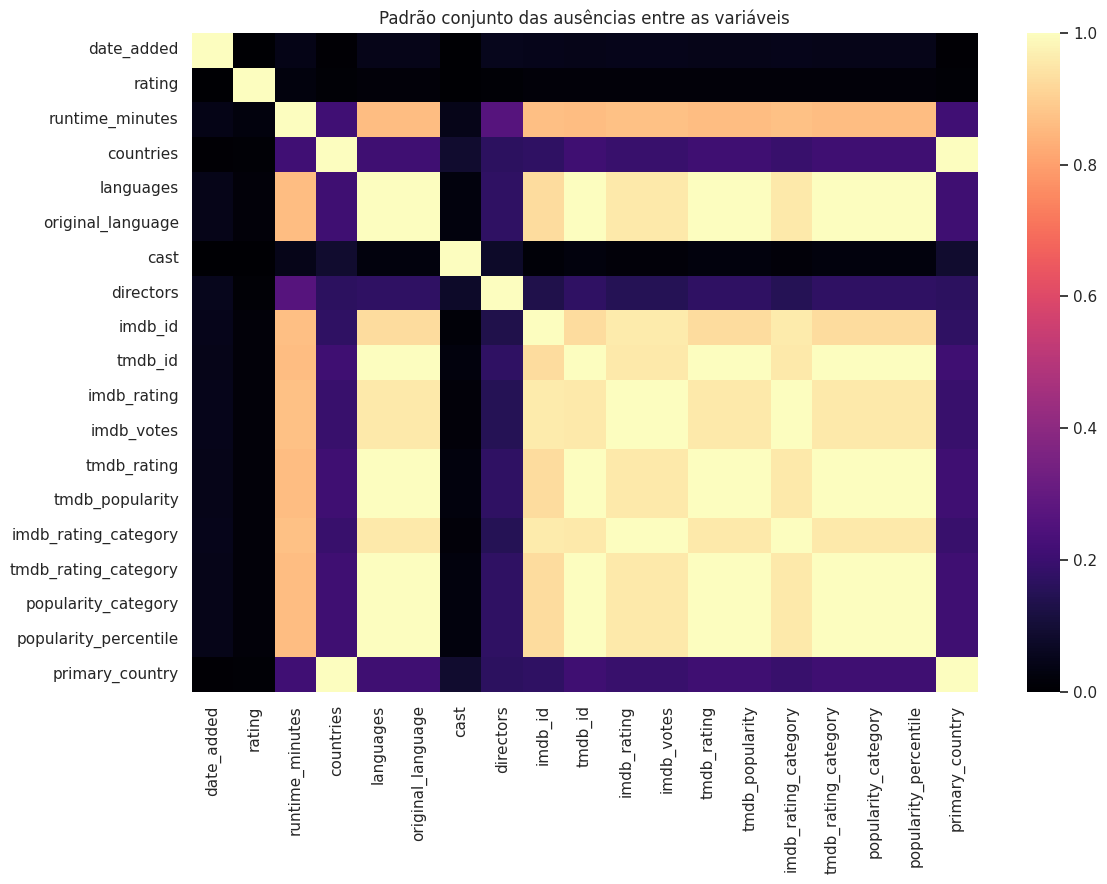

,coluna_1,coluna_2,ausencias_juntas
89,original_language,tmdb_rating_category,2431
86,original_language,tmdb_rating,2431
83,original_language,tmdb_id,2431
91,original_language,popularity_percentile,2431
77,languages,popularity_category,2431
78,languages,popularity_percentile,2431
90,original_language,popularity_category,2431
66,languages,original_language,2431
73,languages,tmdb_rating,2431
74,languages,tmdb_popularity,2431


In [ ]:
# Indicador de ausência (True/False) para todas as colunas com valores faltantes
missing_indicators = df[cols_com_ausentes].isna().astype(int)

# Correlação entre os indicadores de ausência
corr_ausencias = missing_indicators.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_ausencias, cmap="magma", vmin=0, vmax=1, square=False)
plt.title("Padrão conjunto das ausências entre as variáveis")
plt.tight_layout()
plt.show()

# Pares com maior quantidade de ausências simultâneas
coausencias = []
for i, col1 in enumerate(cols_com_ausentes):
    for col2 in cols_com_ausentes[i + 1:]:
        juntas = (df[col1].isna() & df[col2].isna()).sum()
        coausencias.append((col1, col2, juntas))

pd.DataFrame(coausencias, columns=["coluna_1", "coluna_2", "ausencias_juntas"]) \
  .sort_values("ausencias_juntas", ascending=False) \
  .head(15)

**Discussão:** as ausências ocorrem juntas? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- **MCAR:** ausência completamente aleatória, sem relação com variáveis observadas ou com o próprio valor ausente.
- **MAR:** ausência relacionada a outras informações observadas no conjunto.
- **MNAR:** ausência relacionada ao próprio valor que está faltando ou a um mecanismo não observado.

*Resposta:* Como várias variáveis provenientes da mesma fonte externa apresentam quantidades de ausências muito semelhantes, é plausível que exista um padrão de ausência associado ao processo de *matching* e enriquecimento dos títulos. Isso torna **MCAR menos plausível**. Com apenas este dataset, porém, não é possível distinguir de forma definitiva entre MAR e MNAR. A hipótese mais consistente com o processo de integração descrito é MAR: a ausência pode depender de características observáveis do registro e da possibilidade de encontrar correspondência nas bases externas.

No contexto deste dataset:

- **MAR é uma hipótese plausível** quando a ausência depende do processo de integração entre fontes. Por exemplo, determinados títulos podem ser mais difíceis de associar ao IMDb/TMDB devido a diferenças de título, ano ou metadados disponíveis; nesse caso, a ausência está relacionada a informações observáveis do próprio registro e ao procedimento de *matching*.
- **MNAR também não pode ser descartado apenas pelos dados.** Poderia existir algum padrão não observado associado justamente ao valor faltante, mas o notebook não possui evidência suficiente para afirmar isso.

Portanto, a análise visual dos padrões de ausência ajuda a formular hipóteses, mas não prova o mecanismo. A decisão de tratamento deve considerar também a origem e o processo de coleta dos dados.

Como este dataset possui muitas colunas e um volume relevante de valores ausentes, o heatmap entre indicadores de ausência é apropriado. Ele complementa a contagem por coluna e ajuda a identificar blocos de variáveis que tendem a ficar ausentes simultaneamente.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = [
"release_year",
"release_decade",
"content_age",
"runtime_minutes",
"imdb_rating",
"imdb_votes",
"tmdb_rating",
"tmdb_popularity",
"popularity_percentile",
"genre_count",
"country_count",
"data_completeness_score",
"match_confidence"
]

VARS_QUALI = [
"content_id",
"title",
"type",
"release_year_group",
"date_added",
"rating",
"duration",
"description",
"genres",
"countries",
"languages",
"original_language",
"cast",
"directors",
"imdb_id",
"tmdb_id",
"imdb_rating_category",
"tmdb_rating_category",
"popularity_category",
"primary_genre",
"primary_country",
"is_original",
"is_recent_release",
"has_rating",
"has_cast",
"has_director",
"match_method"
]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
release_year,2013.93,2017.00,8.76,1925.00,2021.00,-3.62,17.56
release_decade,2008.51,2010.00,8.90,1920.00,2020.00,-3.10,15.44
content_age,12.07,9.00,8.76,5.00,101.00,3.62,17.56
runtime_minutes,92.99,96.00,35.23,2.00,542.00,0.27,5.67
imdb_rating,6.41,6.50,1.16,1.50,9.40,-0.67,0.61
imdb_votes,36820.77,2771.00,133617.42,5.00,2858413.00,9.39,127.14
tmdb_rating,6.26,6.47,1.44,0.00,10.00,-1.90,6.12
tmdb_popularity,3.86,2.11,5.81,0.01,221.58,13.13,393.95
popularity_percentile,50.01,50.01,28.87,0.02,100.00,0.00,-1.20
genre_count,2.19,2.00,0.79,1.00,3.00,-0.35,-1.30


**Discussão:** olhando a tabela, quais variáveis parecem assimétricas (`|skewness|` acima de 1) ou com cauda pesada (`|kurtosis|` maior que 2)?

*Resposta:* As maiores assimetrias aparecem em `tmdb_popularity` (fortemente à direita), `imdb_votes` (fortemente à direita), `country_count` e nas variáveis temporais `release_year`/`content_age`. Também há curtose elevada em várias delas, especialmente `tmdb_popularity`, `imdb_votes`, `country_count` e `release_year`. Isso é coerente com o domínio: poucos títulos concentram grande volume de votos/popularidade, enquanto o catálogo é dominado por produções recentes e contém um número menor de obras antigas.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


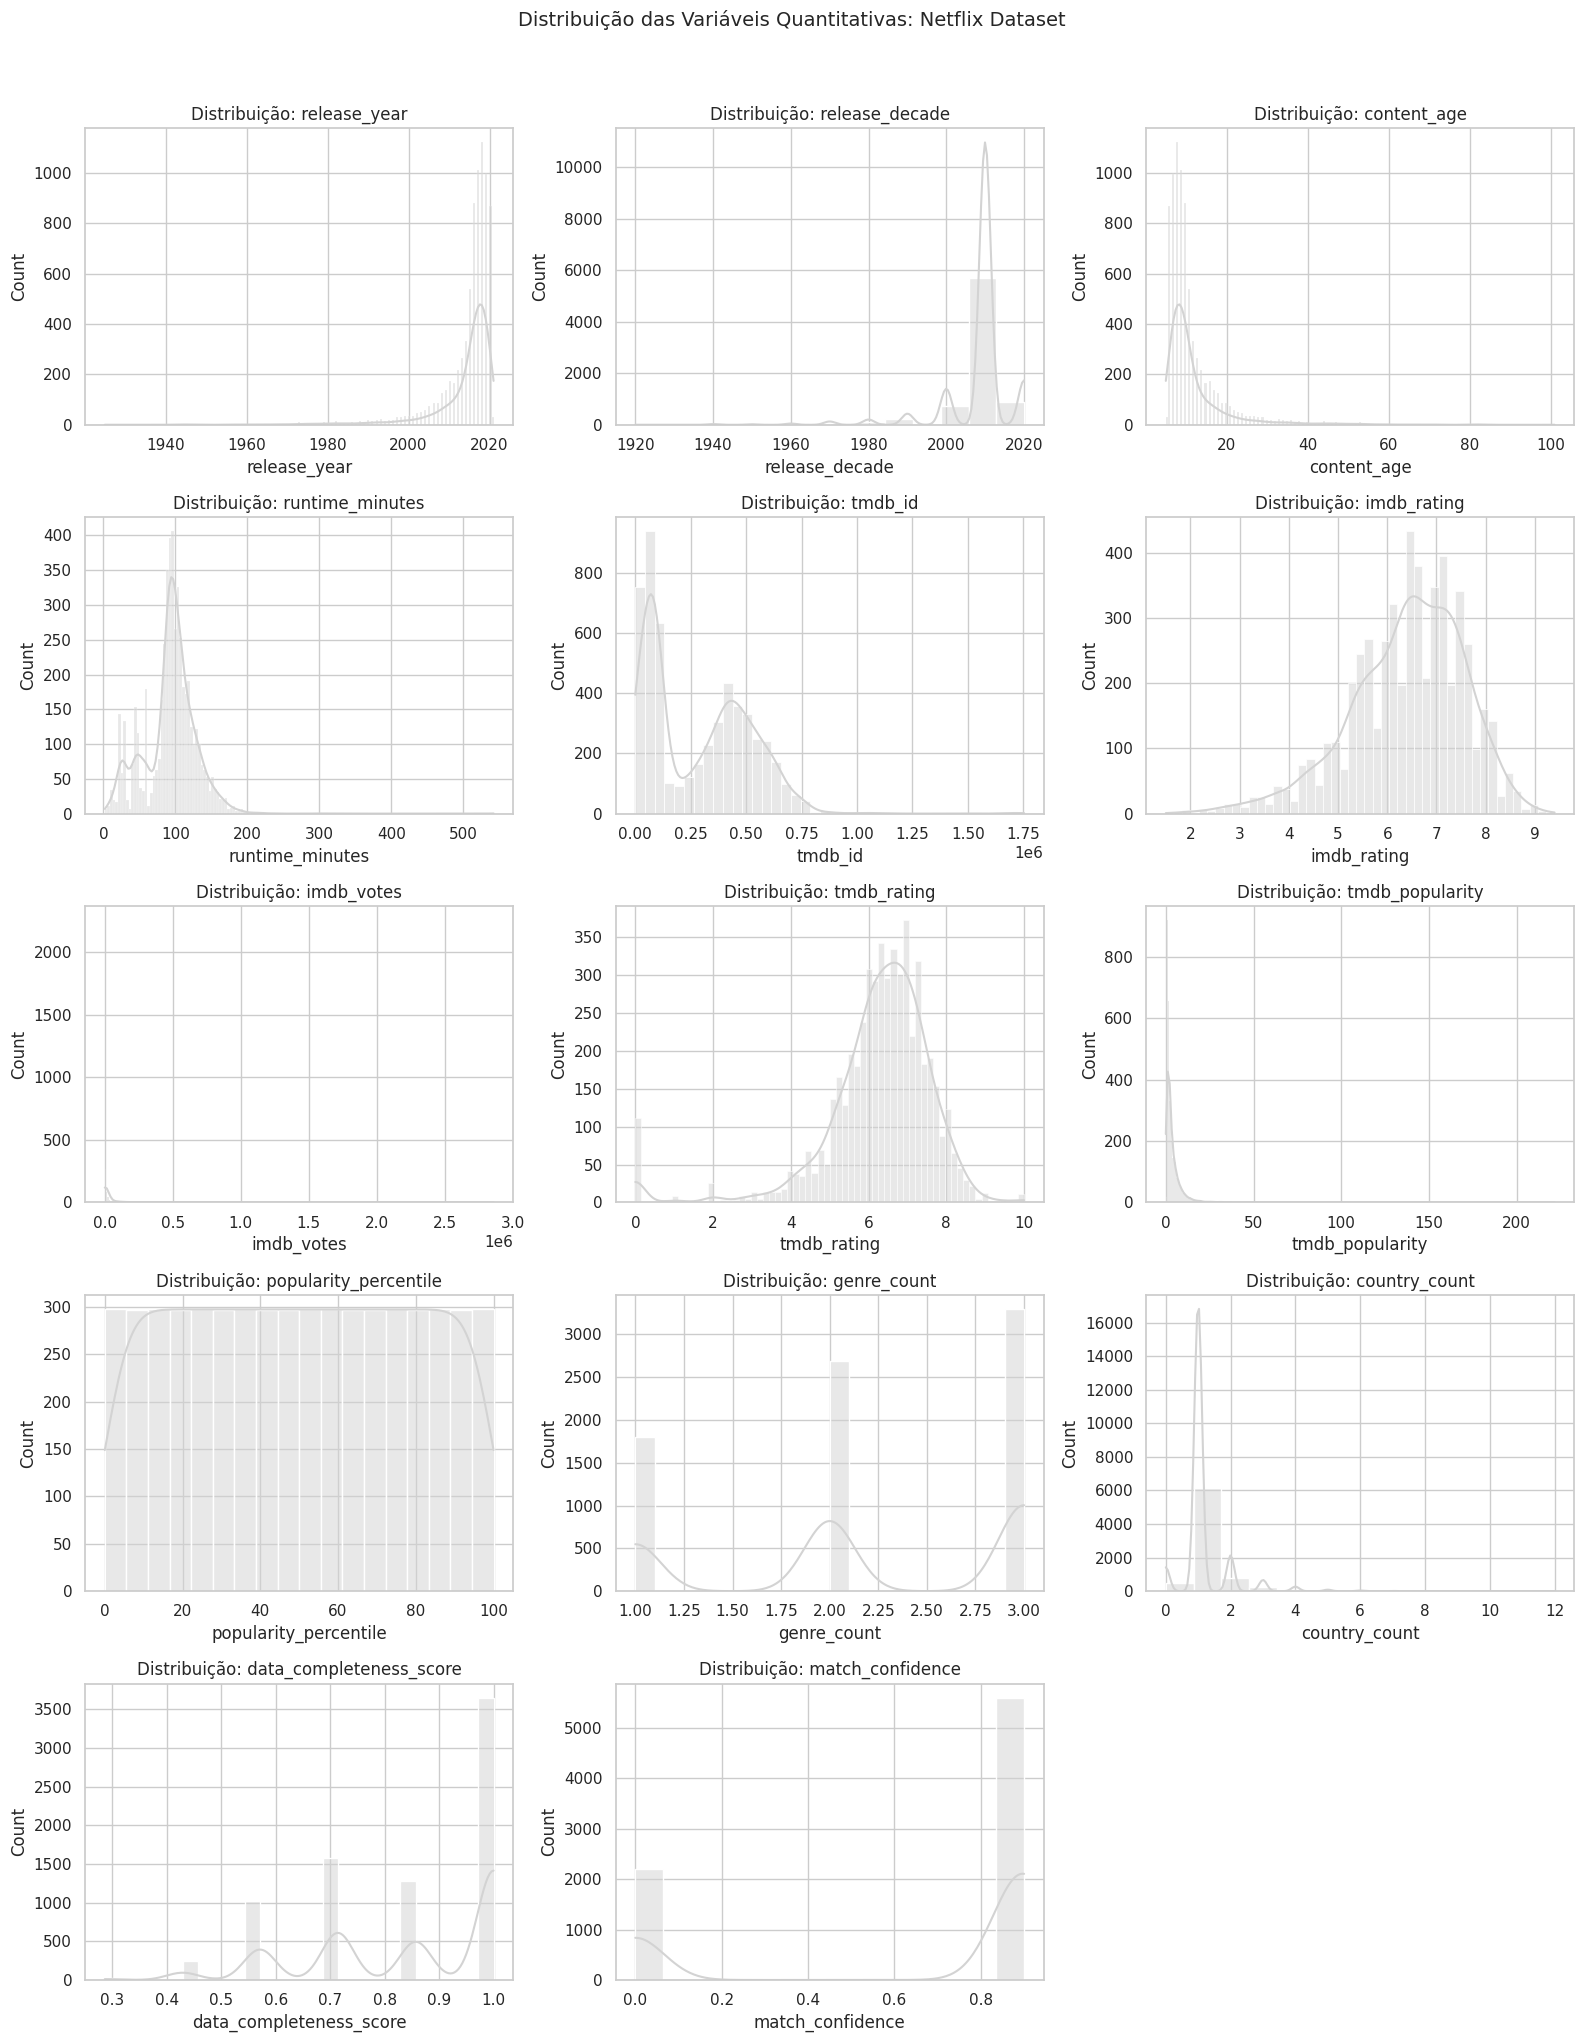

In [ ]:
cols_quant = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

num_vars = len(cols_quant)

cols_grid = 3
rows_grid = (num_vars + cols_grid - 1) // cols_grid

fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(16, 4 * rows_grid))
axes = axes.ravel()

for i, col in enumerate(cols_quant):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(f"Distribuição: {col}")

for ax in axes[num_vars:]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Netflix Dataset", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

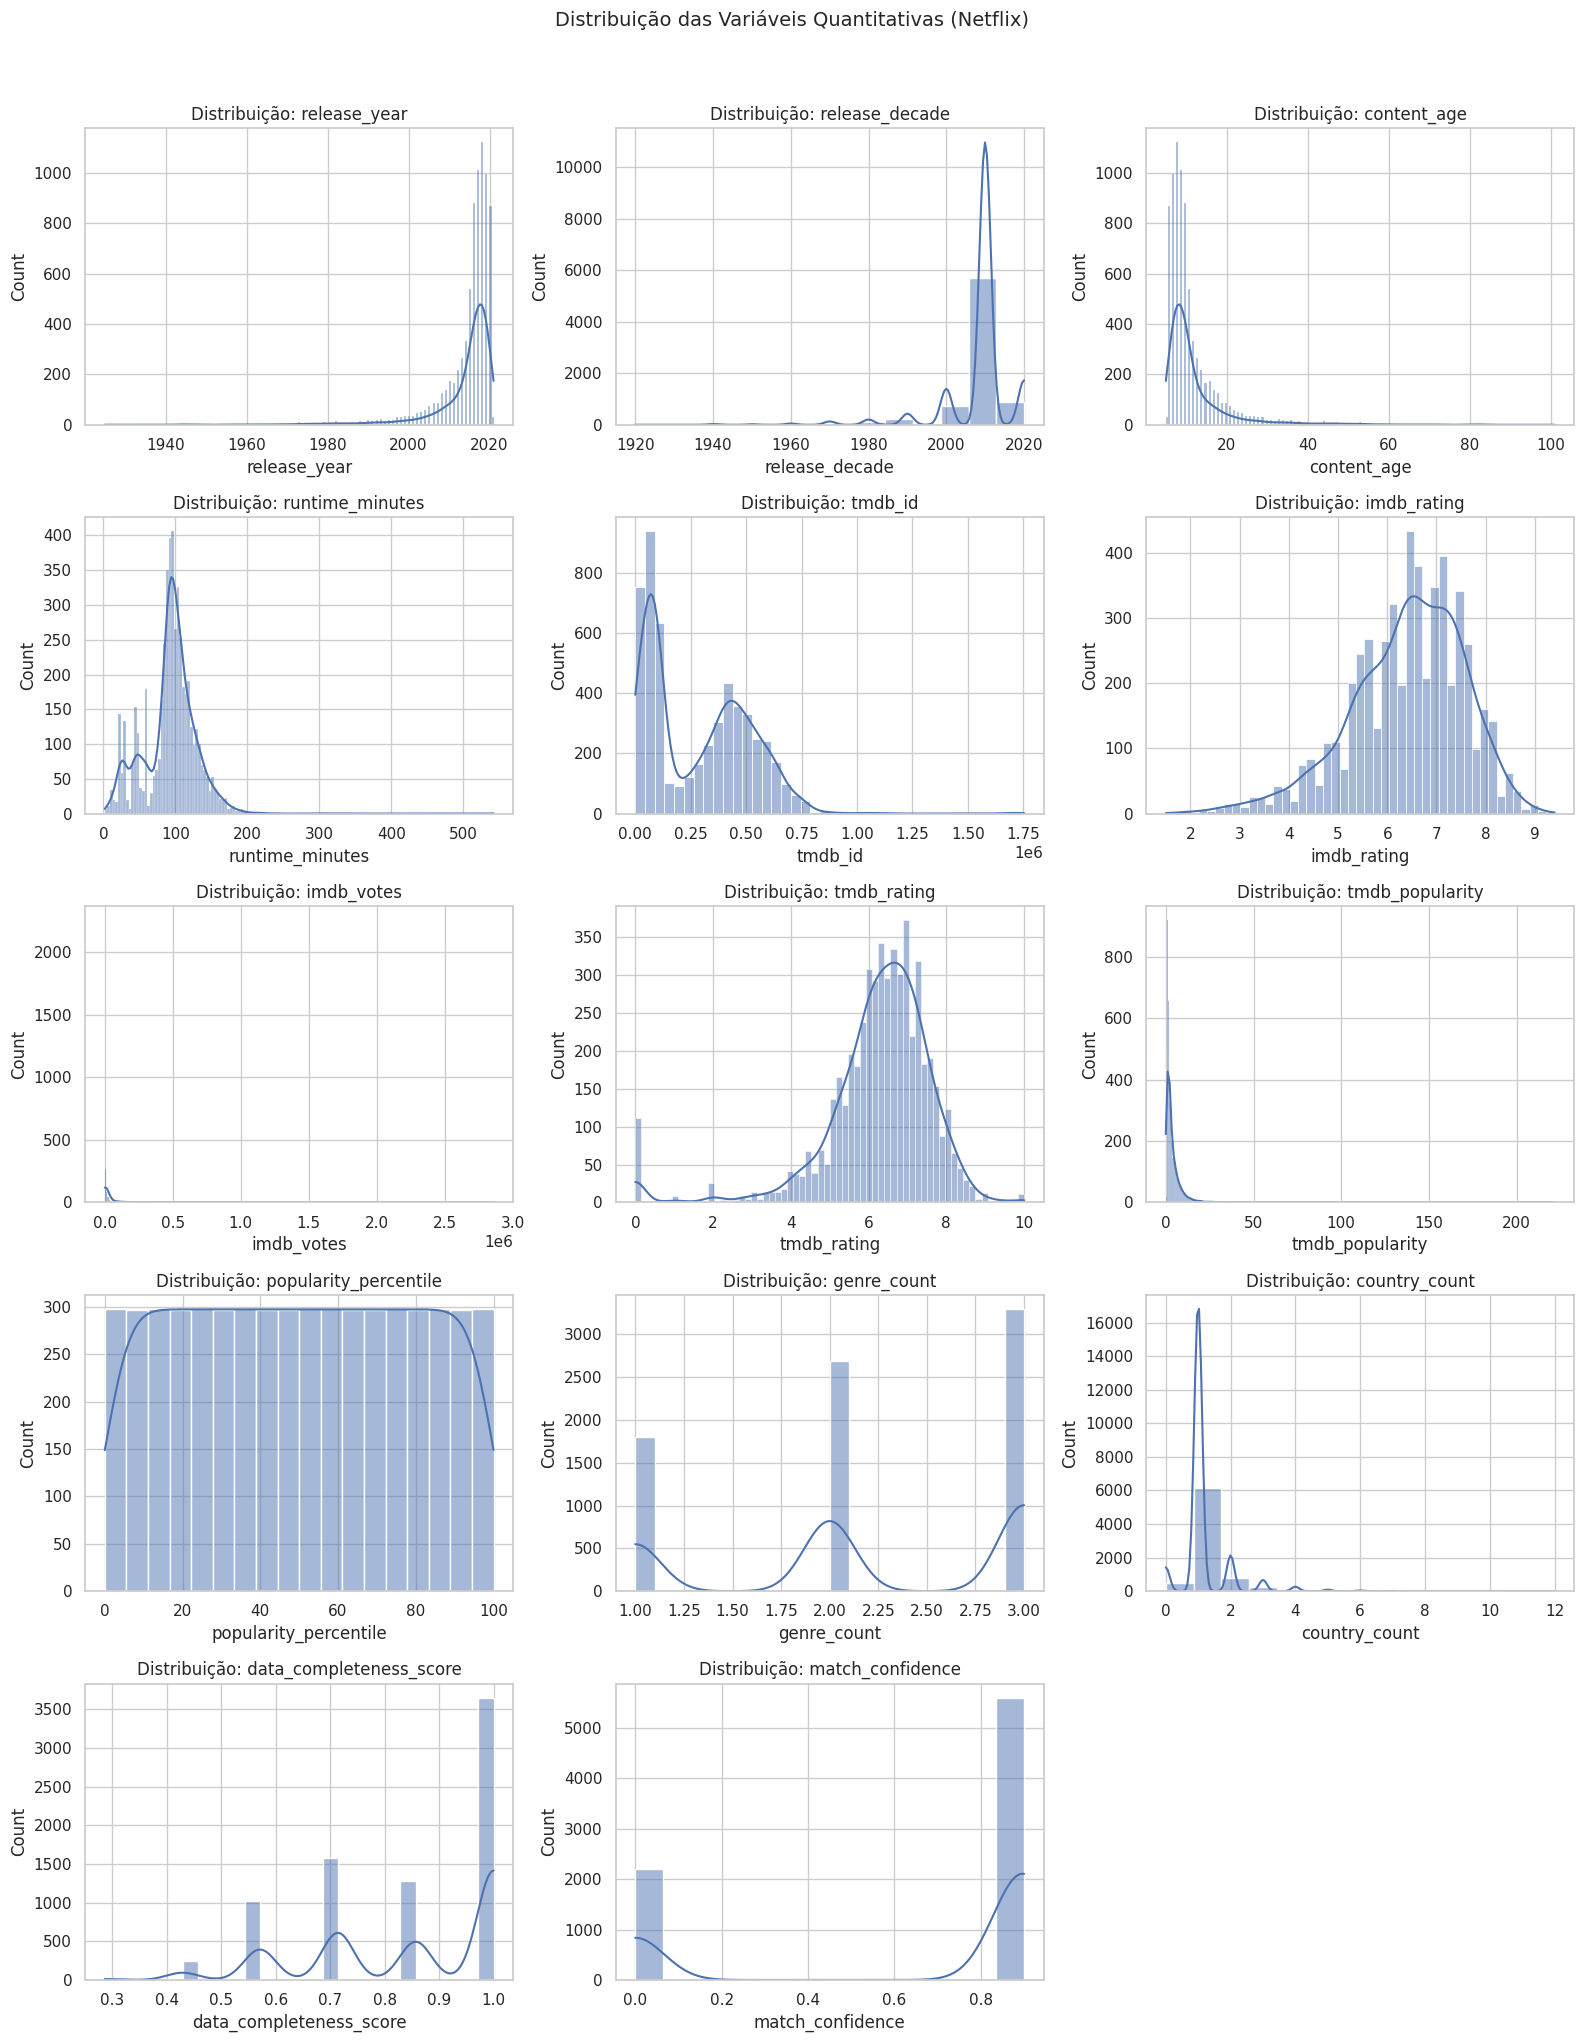

In [ ]:
cols_quant = [c for c in df.select_dtypes(include=['int64', 'float64']).columns if c in df.columns]

num_vars = len(cols_quant)

if num_vars > 0:
    cols_grid = 3
    rows_grid = (num_vars + cols_grid - 1) // cols_grid

    fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(16, 4 * rows_grid))

    if num_vars == 1:
        axes = [axes]
    else:
        axes = axes.ravel()

    for i, col in enumerate(cols_quant):
        sns.histplot(data=df, x=col, kde=True, ax=axes[i])
        axes[i].set_title(f"Distribuição: {col}")

    for ax in axes[num_vars:]:
        ax.axis("off")

    fig.suptitle("Distribuição das Variáveis Quantitativas (Netflix)", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma coluna numérica foi encontrada no DataFrame.")

**Para discutir:** agora que as distribuições estão em painéis separados e na mesma escala, fica mais fácil comparar os formatos. Algumas variáveis apresentam diferenças visuais entre `Movie` e `TV Show`, especialmente duração, avaliações e ano de lançamento. Essas diferenças serão testadas formalmente mais adiante.

#### Testes de Aderência

*Será que a nota do IMDb segue uma distribuição normal?*

Usaremos o **Shapiro-Wilk** como teste de aderência para normalidade, junto com o **QQ-Plot** como apoio visual. A variável analisada será `imdb_rating`.

Shapiro-Wilk — imdb_rating: estatística=0.9740, p-valor=2.144e-30
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5460.
  res = hypotest_fun_out(*samples, **kwds)


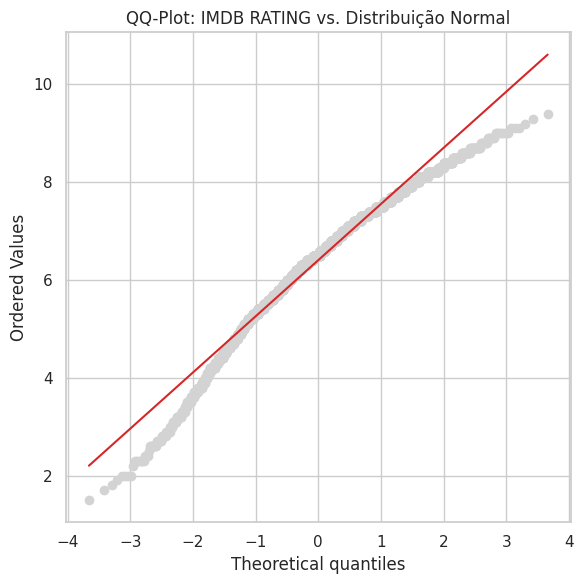

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["imdb_rating"].dropna())
print(f"Shapiro-Wilk — imdb_rating: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — IMDB RATING """

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["imdb_rating"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: IMDB RATING vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos seguissem a reta de referência de perto, a distribuição seria mais compatível com uma normal. Desvios sistemáticos, principalmente nas pontas, indicam assimetria e/ou caudas diferentes da normal — coerentes com o resultado do Shapiro-Wilk.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** amostras grandes deixam o Shapiro-Wilk muito sensível a pequenos desvios. Para `imdb_rating`, temos mais de 5 mil observações válidas, e o próprio SciPy alerta que o p-valor pode perder precisão acima de 5.000 casos. Por isso, a decisão não deve se apoiar apenas no p-valor: usamos também assimetria, curtose, histograma e QQ-Plot.
- **Como afirmar o resultado:** quando o teste rejeita H0 (`p < 0.05`), a afirmação correta é que há evidência estatística **contra** a normalidade. Quando não rejeita, isso não prova normalidade; apenas indica falta de evidência suficiente para rejeitá-la.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7786.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5115.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5355.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
release_year,0.6132,0.0,True
release_decade,0.5907,0.0,True
content_age,0.6132,0.0,True
runtime_minutes,0.9528,0.0,True
imdb_rating,0.9740,0.0,True
imdb_votes,0.2721,0.0,True
tmdb_rating,0.8523,0.0,True
tmdb_popularity,0.4556,0.0,True
popularity_percentile,0.9549,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende da escolha do número de *bins*: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil para comparar duas distribuições lado a lado.

Aqui usamos `imdb_rating`, comparando `Movie` e `TV Show`.

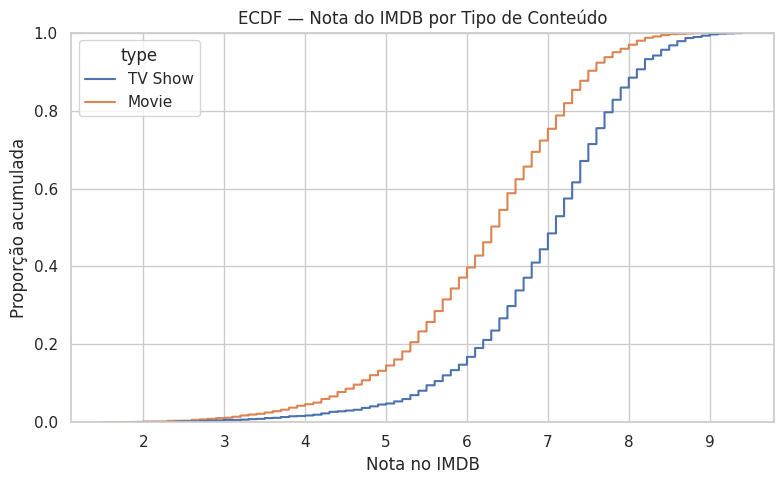

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(
    data=df,
    x="imdb_rating",
    hue="type"
)
plt.title("ECDF — Nota do IMDB por Tipo de Conteúdo")
plt.xlabel("Nota no IMDB")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva indica a fração dos títulos daquele grupo com nota IMDb menor ou igual ao valor mostrado. Onde as curvas de `Movie` e `TV Show` se afastam mais, existe maior diferença entre as distribuições acumuladas dos dois tipos de conteúdo.

### Métricas de Tendência Central

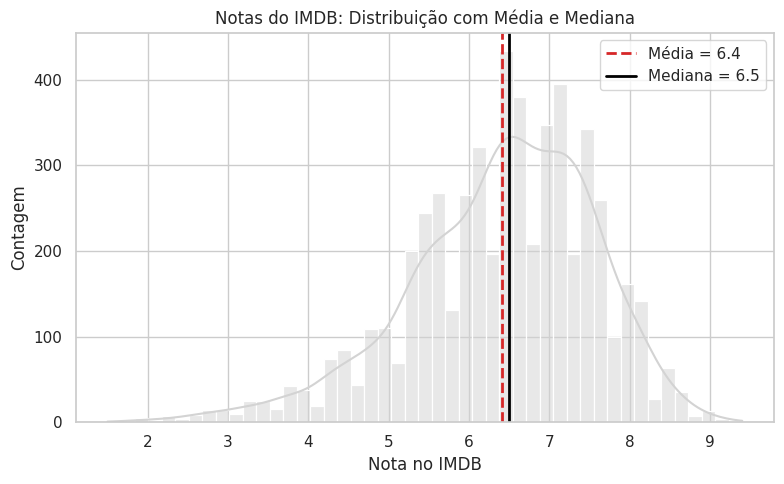

In [ ]:
media_imdb = df["imdb_rating"].mean()
mediana_imdb = df["imdb_rating"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="imdb_rating", kde=True, color=COR_NEUTRA)

plt.axvline(media_imdb, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_imdb:.1f}")
plt.axvline(mediana_imdb, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_imdb:.1f}")

plt.title("Notas do IMDB: Distribuição com Média e Mediana")
plt.xlabel("Nota no IMDB")
plt.ylabel("Contagem")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

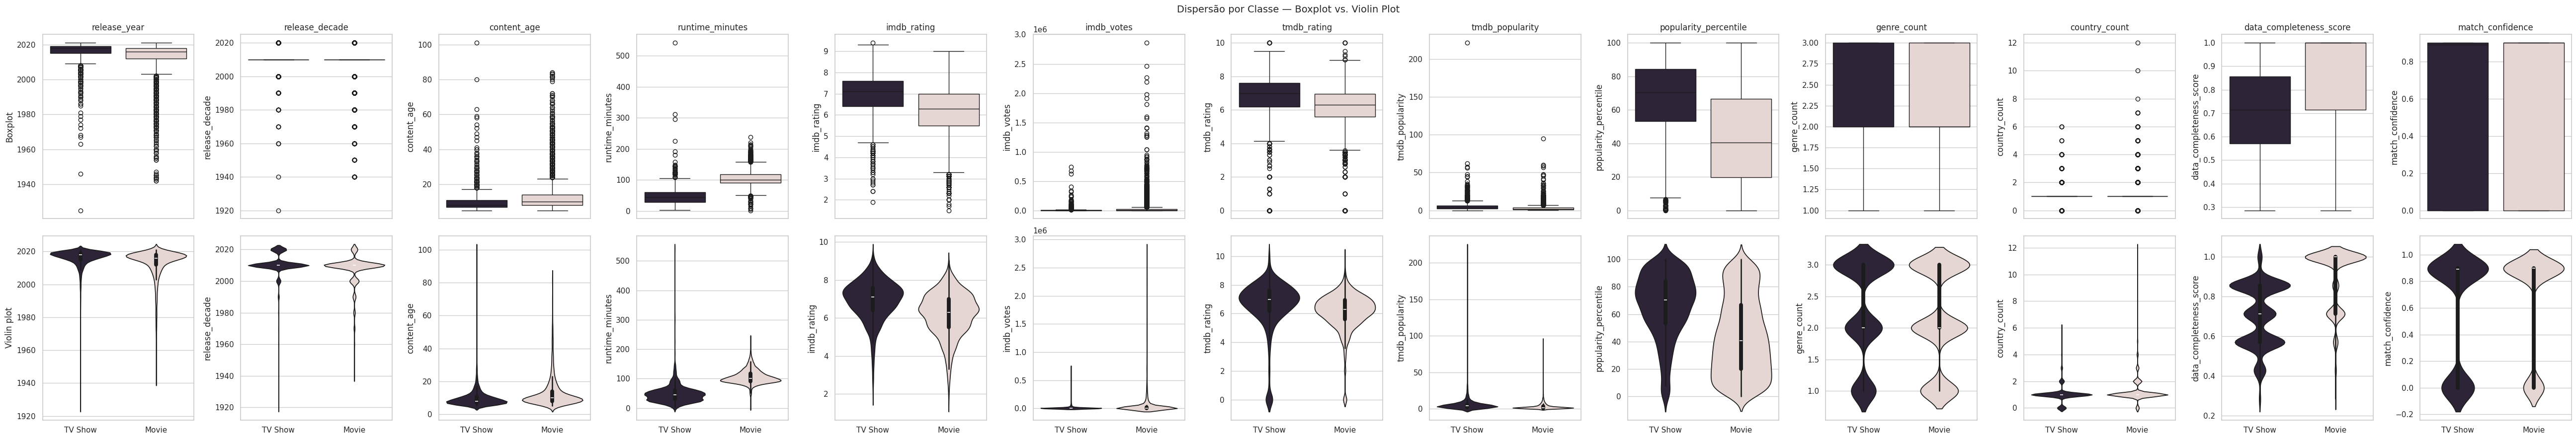

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Movie": COR_CONTEXTO, "TV Show": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="type", y=col, hue="type",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="type", y=col, hue="type",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** Alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Movie" e "TV Show"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar o tipo de conteúdo do catálogo.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos informação para decidir como tratar tanto os dados ausentes (como em `imdb_rating`, `tmdb_rating` e `directors`) quanto os outliers das variáveis quantitativas. Depois do tratamento, rodamos a estatística descritiva novamente para comparar o efeito das escolhas e fechar o ciclo iterativo da EDA.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "percent_outliers": f"{(n_outliers / len(df)) * 100:.2f}%"
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,percent_outliers
release_year,2005.5,2025.5,745,9.57%
release_decade,2010.0,2010.0,2076,26.66%
content_age,0.5,20.5,745,9.57%
runtime_minutes,32.0,160.0,544,6.99%
imdb_rating,3.45,9.45,99,1.27%
imdb_votes,-20965.5,36402.5,900,11.56%
tmdb_rating,3.64,9.19,234,3.01%
tmdb_popularity,-4.11,9.97,388,4.98%
popularity_percentile,-49.97,149.99,0,0.00%
genre_count,0.5,4.5,0,0.00%


### Visualizando os Outliers

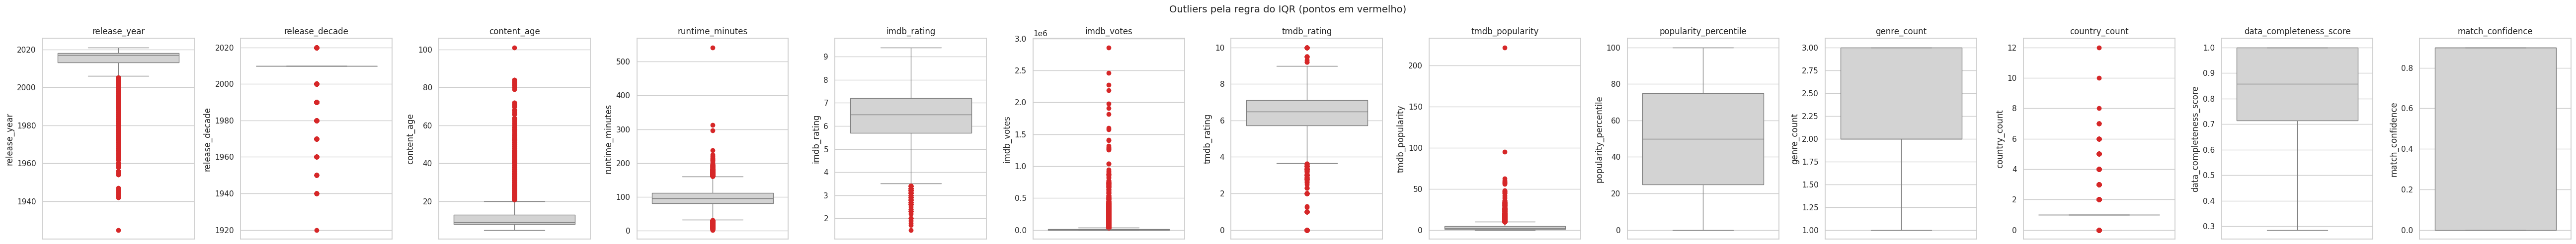

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

Pra discutir: o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições plausíveis | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em release_year, country_count, imdb_votes, runtime_minutes e tmdb_popularity): eles parecem comercialmente e historicamente plausíveis (produções reais podem ter múltiplos países envolvidos, milhões de avaliações, extrema popularidade ou ser obras clássicas e curtas-metragens), ou parecem violar algum limite do domínio de entretenimento? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

---

Análise do Nosso Dataset:

1. Outliers Estatísticos (Legítimos):
- imdb_votes (11,56%) e tmdb_popularity (4,98%): Refletem a dinâmica real da indústria de entretenimento, onde uma pequena parcela de títulos atinge enorme apelo popular (distribuição de cauda longa). São dados autênticos.
- release_year / content_age (9,57%): Títulos anteriores a 2005 são detectados como outliers pelo IQR devido ao predomínio de lançamentos recentes nas plataformas de streaming, mas representam produções clássicas perfeitamente válidas.
- country_count (21,28%): Co-produções internacionais envolvendo múltiplos países são uma prática comum do mercado.
- runtime_minutes (6,99%): Variações legítimas de formato (curtas-metragens ou filmes épicos de longa duração).

Recomendação: Manter esses dados no dataset ou aplicar transformações logarítmicas (no caso de votos e popularidade) para suavizar a assimetria, já que representam fenômenos reais do domínio.

2. Outliers de Domínio (Anomalias Conceituais / Negócio):
- runtime_minutes = 0 ou duração excessiva (ex: > 1.000 min em filme único): Viola a regra plausível de duração comercial de um título, devendo ser investigado se refere-se a um erro de cadastro ou a uma minissérie/coleção agrupada incorretamente.
- imdb_rating ou tmdb_rating fora da escala [0, 10]: Pontuações abaixo de 0 ou acima de 10 violam as regras do domínio das plataformas de avaliação.

Recomendação: Investigar os casos pontuais. Se confirmada a violação da regra de negócio, ajustar ou remover a observação.

3. Erros de Dados (Falhas de Coleta / Input):
- release_year no futuro ou ano inconsistente (ex: ano > ano atual ou valores negativos): Representa inconsistência direta na inserção/extração dos metadados.
- data_completeness_score fora da escala [0, 1] ou percentuais negativos em variáveis de proporção.

Recomendação: Corrigir a partir da fonte/metadados originais se possível; caso contrário, remover as linhas afetadas como última opção.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que observamos: o volume de dados ausentes nas métricas de avaliação é expressivo (aproximadamente 30% do dataset em `imdb_rating` e `tmdb_rating`). Remover todas essas observações causaria perda considerável de informação. Para manter o tamanho da amostra e preservar uma estratégia simples compatível com a atividade, será utilizada **imputação pela mediana** nas duas notas, já que as distribuições não são normais.

Essa decisão tem uma limitação importante: imputar muitos valores pela mediana cria concentração artificial no centro da distribuição. Por isso, a comparação "antes x depois" será usada para documentar esse efeito, e análises futuras que dependam da distribuição original das notas devem considerar métodos de imputação mais sofisticados ou trabalhar apenas com valores observados.

In [ ]:
df_antes = df.copy()
linhas_antes = df.shape[0]

cols_para_imputar = ["imdb_rating", "tmdb_rating"]

for col in cols_para_imputar:
    mediana = df[col].median()
    df[col] = df[col].fillna(mediana)

df["primary_genre"] = df["primary_genre"].fillna("Não informado")

linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Registros mantidos: {linhas_depois}")
print(f"Valores nulos restantes em imdb_rating: {df['imdb_rating'].isnull().sum()}")

Linhas antes: 7786 | Linhas depois: 7786 | Registros mantidos: 7786
Valores nulos restantes em imdb_rating: 0


In [ ]:
# Exportação dos dados para o dashboard Streamlit (original e tratado)
from pathlib import Path
pasta_dados = Path("data") if Path("data").exists() else Path("../data")
pasta_dados.mkdir(parents=True, exist_ok=True)
df_antes.to_csv(pasta_dados / "netflix_original.csv", index=False)
df.to_csv(pasta_dados / "netflix_tratado.csv", index=False)
print("Datasets exportados para:", pasta_dados.resolve())


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui não vamos remover automaticamente. Pelos valores encontrados (dentro de faixas comercialmente plausíveis para o mercado de entretenimento, ainda que raras), a classificação mais provável é de Outliers Estatísticos legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é manter (a informação é real e pode ser comercialmente relevante — por exemplo, exatamente os títulos com volume extremo de votos ou popularidade gigante são os blockbusters e grandes sucessos do catálogo) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), transformar.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em imdb_votes — útil caso, mais adiante em análises futuras, a assimetria acentuada atrapalhe algum teste ou modelo.

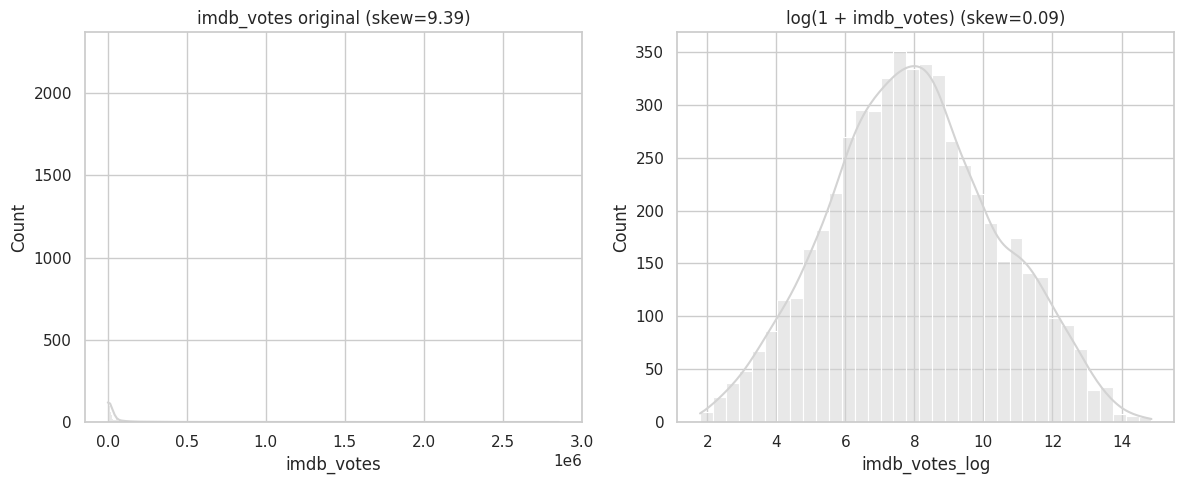

In [ ]:
df["imdb_votes_log"] = np.log1p(df["imdb_votes"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="imdb_votes", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"imdb_votes original (skew={df['imdb_votes'].skew():.2f})")

sns.histplot(data=df, x="imdb_votes_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + imdb_votes) (skew={df['imdb_votes_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Discussão:** a transformação logarítmica reduziu visivelmente a assimetria de `imdb_votes`? Mantivemos `imdb_votes_log` apenas como demonstração e não a utilizaremos nas próximas seções. A ideia é mostrar uma alternativa quando uma variável positiva apresenta cauda direita muito longa.

Nem todo outlier deve ser removido. Antes de decidir, classificamos o valor: estatisticamente raro mas plausível (manter/transformar), violação de regra de domínio (investigar) ou erro claro de coleta/digitação (corrigir ou remover como última opção).

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
release_year,2013.93,2017.00,8.76,1925.00,2021.00,-3.62,17.56
release_decade,2008.51,2010.00,8.90,1920.00,2020.00,-3.10,15.44
content_age,12.07,9.00,8.76,5.00,101.00,3.62,17.56
runtime_minutes,92.99,96.00,35.23,2.00,542.00,0.27,5.67
imdb_rating,6.43,6.50,0.98,1.50,9.40,-0.89,2.22
imdb_votes,36820.77,2771.00,133617.42,5.00,2858413.00,9.39,127.14
tmdb_rating,6.33,6.47,1.20,0.00,10.00,-2.43,10.60
tmdb_popularity,3.86,2.11,5.81,0.01,221.58,13.13,393.95
popularity_percentile,50.01,50.01,28.87,0.02,100.00,0.00,-1.20
genre_count,2.19,2.00,0.79,1.00,3.00,-0.35,-1.30


### Comparando "antes" x "depois"

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
release_year,-3.619,-3.619,17.563,17.563,0.000,0.000
release_decade,-3.102,-3.102,15.438,15.438,0.000,0.000
content_age,3.619,3.619,17.563,17.563,0.000,0.000
runtime_minutes,0.268,0.268,5.672,5.672,0.000,0.000
imdb_rating,-0.673,-0.888,0.606,2.219,-0.215,1.613
imdb_votes,9.391,9.391,127.139,127.139,0.000,0.000
tmdb_rating,-1.900,-2.431,6.124,10.603,-0.531,4.479
tmdb_popularity,13.130,13.130,393.952,393.952,0.000,0.000
popularity_percentile,0.000,0.000,-1.200,-1.200,0.000,0.000
genre_count,-0.352,-0.352,-1.302,-1.302,0.000,0.000


### Análise e Comparação das Estatísticas Descritivas (Pós-Tratamento)

**Discussão dos Resultados:**

1. **Impacto Conservador:** Ao comparar os dados com a análise inicial da Seção 3, observa-se que as métricas de tendência central (média e mediana) e de dispersão (desvio padrão e IQR) para variáveis como `imdb_rating`, `tmdb_rating` e `runtime_minutes` praticamente não sofreram alterações expressivas.
2. **Justificativa Metodológica:** Esse resultado é esperado e positivo:
   - A remoção/tratamento de apenas uma pequena fração das linhas (dados ausentes/nulos) evitou a perda excessiva de informação no catálogo da Netflix.
   - Ao optar por **manter os outliers de duração** (filmes muito curtos, como curtas-metragens, ou muito longos, como épicos e documentários), preservou-se a variabilidade real e legítima do ecossistema de conteúdo da plataforma.
3. **Conclusão:** A estabilidade dos valores estatísticos confirma que a etapa de limpeza e tratamento foi executada de forma prudente e conservadora, garantindo a integridade e representatividade dos dados para as próximas etapas de análise bivariada e modelagem.

**A distribuição da nota do IMDb ainda rejeita normalidade?**

Vamos rodar o mesmo teste de Shapiro-Wilk da Seção 3 na variável `imdb_rating` (ou `runtime_minutes`), utilizando os dados tratados.

In [ ]:

stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["imdb_rating"].dropna())

print(f"Shapiro-Wilk (depois) — imdb_rating: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

if p_valor_sw_depois < 0.05:
    print("Conclusão: O p-valor é menor que 0.05 (p < 0.05). Rejeitamos a hipótese nula de normalidade (a variável NÃO segue distribuição normal).")
else:
    print("Conclusão: O p-valor é maior ou igual a 0.05. Não rejeitamos a hipótese de normalidade.")

Shapiro-Wilk (depois) — imdb_rating: estatística=0.9237, p-valor=1.443e-52
Conclusão: O p-valor é menor que 0.05 (p < 0.05). Rejeitamos a hipótese nula de normalidade (a variável NÃO segue distribuição normal).


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7786.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`imdb_rating` e `runtime_minutes`), comparando a versão original (`df_antes`) com a tratada (`df`).

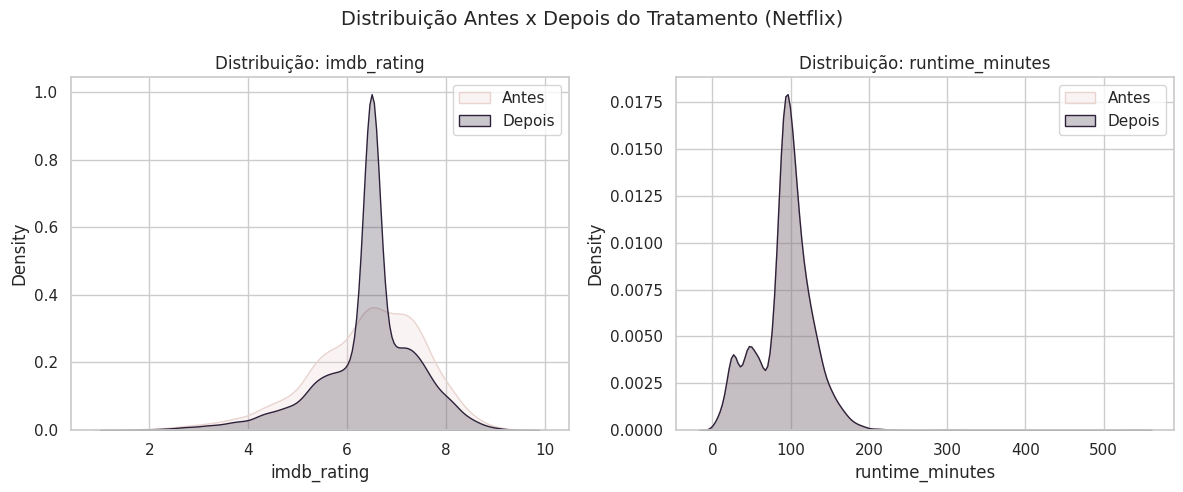

In [ ]:
cols_comparacao = ["imdb_rating", "runtime_minutes"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, cols_comparacao):
    if col in df.columns:
        if 'df_antes' in locals() and col in df_antes.columns:
            sns.kdeplot(df_antes[col].dropna(), color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)

        sns.kdeplot(df[col].dropna(), color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)

        ax.set_title(f"Distribuição: {col}")
        ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento (Netflix)", fontsize=14)
plt.tight_layout()
plt.show()

### Discussão: Comparação das Distribuições Antes x Depois

Ao analisar as curvas de densidade (KDE) da imagem, podemos tirar duas conclusões principais:

1. **Duração (`runtime_minutes`):**
   - As curvas "Antes" e "Depois" estão **perfeitamente sobrepostas**. Isso confirma que a remoção de dados faltantes ou a manutenção dos outliers não distorceu a distribuição original de duração dos títulos.

2. **Avaliação IMDb (`imdb_rating`):**
   - Houve uma **mudança visível na distribuição**. A curva "Depois" (roxa) apresenta um pico mais acentuado (*leptocúrtico*) na faixa entre 6.5 e 7.0.
   - **Por que isso aconteceu?** O método de tratamento/imputação de valores ausentes aplicado à variável `imdb_rating` concentrou um volume significativo de registros ao redor da tendência central (média/mediana), reduzindo ligeiramente a variância nas caudas da distribuição.

> **Conclusão:** Essa comparação gráfica demonstra na prática a importância de checar as distribuições "Antes x Depois", pois técnicas de tratamento de nulos (como preenchimento pela média/mediana) podem alterar a forma da distribuição, algo que estatísticas simples por vezes não revelam sozinhas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
cols_quali = [
    col for col in df.select_dtypes(include=['object', 'category']).columns
    if df[col].nunique() <= 30
]

for col in cols_quali:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- Frequências: {col} ---")
    tabela_freq = pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1)
    print(tabela_freq)


--- Frequências: type ---
         absoluta  relativa
type                       
Movie        5376      0.69
TV Show      2410      0.31

--- Frequências: release_year_group ---
                    absoluta  relativa
release_year_group                    
2016-2019               4011     0.515
2010-2015               1699     0.218
2020-2022                899     0.115
2000s                    728     0.094
Pre-2000                 449     0.058

--- Frequências: rating ---
          absoluta  relativa
rating                      
TV-MA         2862     0.368
TV-14         1931     0.248
TV-PG          806     0.104
R              665     0.085
PG-13          386     0.050
TV-Y           280     0.036
TV-Y7          271     0.035
PG             247     0.032
TV-G           194     0.025
NR              84     0.011
G               39     0.005
TV-Y7-FV         6     0.001
UR               5     0.001
NC-17            3     0.000

--- Frequências: imdb_rating_category ---
           

#### Visualizando as frequências

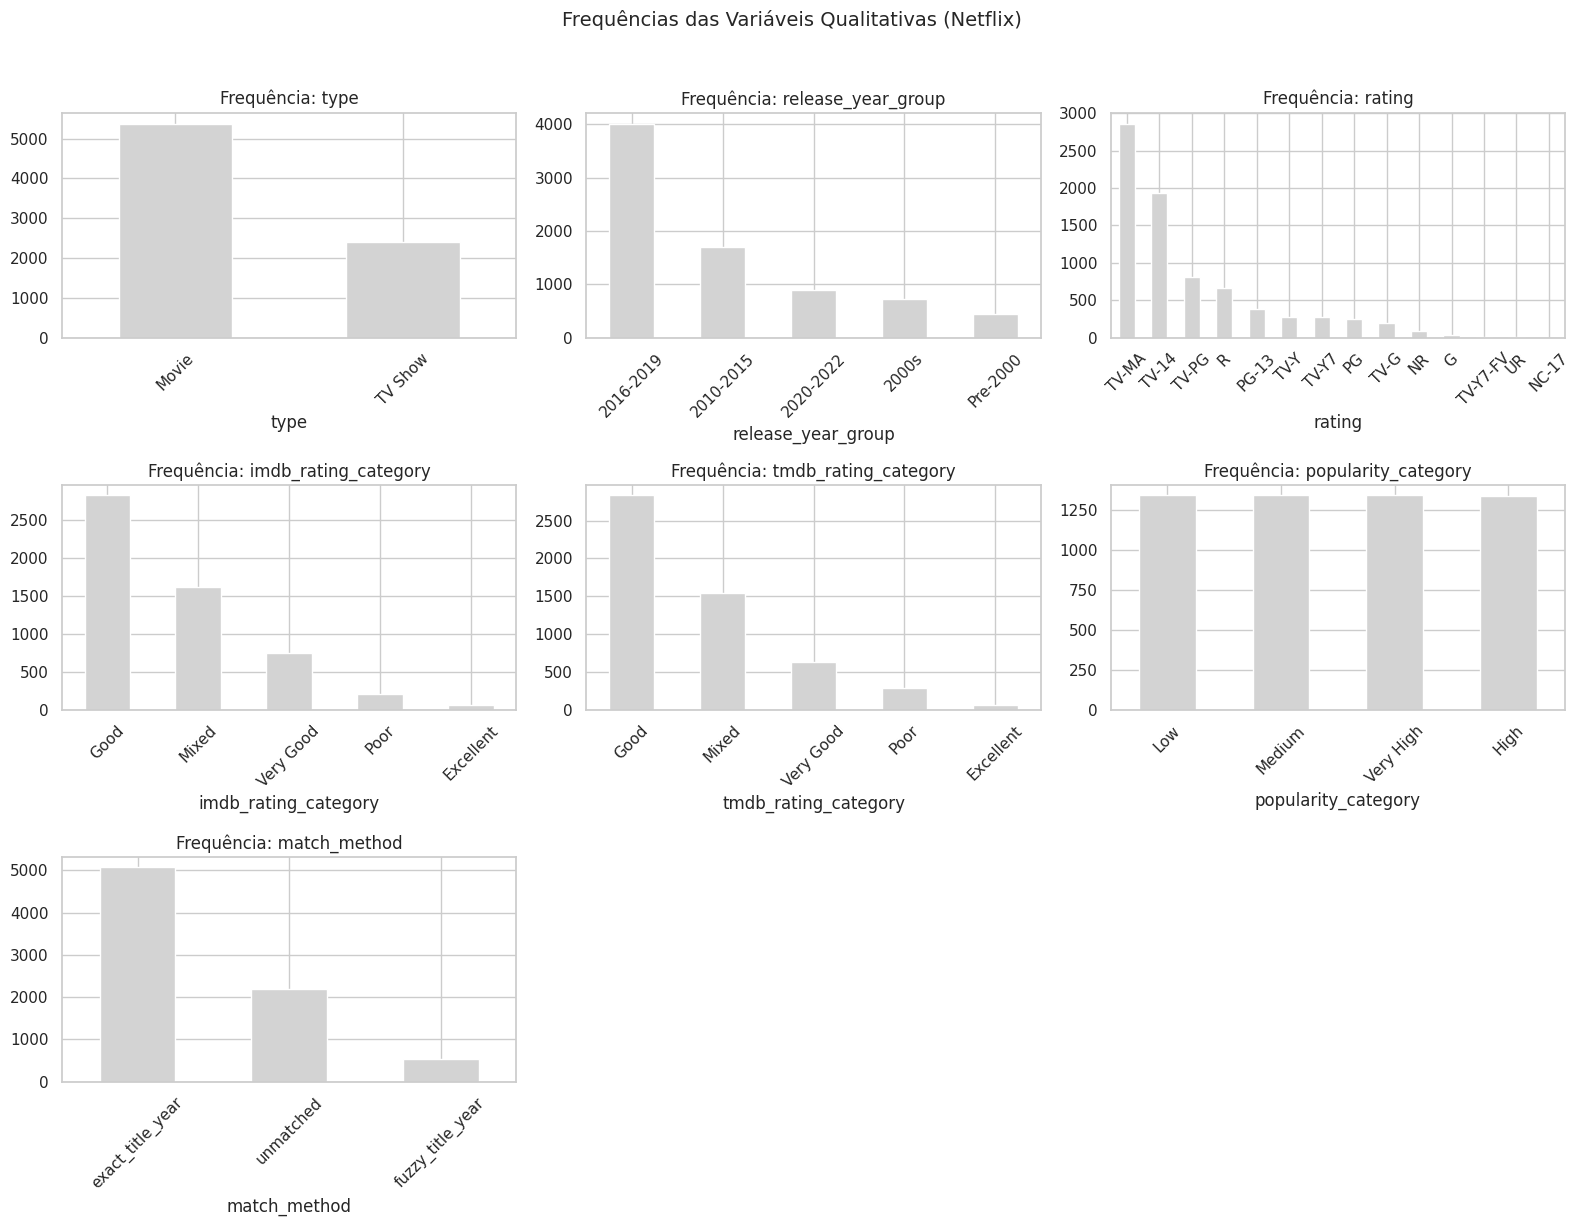

In [ ]:
cols_quali = [
    col for col in df.select_dtypes(include=['object', 'category']).columns
    if df[col].nunique() <= 15
]

num_vars = len(cols_quali)

if num_vars > 0:
    cols_grid = 3
    rows_grid = (num_vars + cols_grid - 1) // cols_grid

    fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(16, 4 * rows_grid))

    if num_vars == 1:
        axes = [axes]
    else:
        axes = axes.ravel()

    for i, col in enumerate(cols_quali):
        df[col].value_counts().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
        axes[i].set_title(f"Frequência: {col}")
        axes[i].tick_params(axis="x", rotation=45)

    for ax in axes[num_vars:]:
        ax.axis("off")

    fig.suptitle("Frequências das Variáveis Qualitativas (Netflix)", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma variável qualitativa adequada para plotagem foi encontrada.")

### Análise Visual das Frequências Qualitativas

Com base nos gráficos de barras gerados para as variáveis categóricas do catálogo, destacam-se os seguintes padrões:

1. **Predomínio de Filmes (`type`):**
   - O catálogo é predominantemente composto por filmes (`Movie`), superando o volume de séries (`TV Show`) por uma proporção de mais de 2 para 1.

2. **Concentração em Produções Recentes (`release_year_group`):**
   - A esmagadora maioria dos títulos foi lançada entre **2016 e 2019**, com uma queda a partir de 2020 e presença bastante reduzida para conteúdos anteriores ao ano 2000.

3. **Perfil do Público Target (`rating`):**
   - Há uma forte concentração nas classificações **`TV-MA`** (conteúdo adulto) e **`TV-14`**, indicando que o foco principal da plataforma nesta amostragem é o público jovem-adulto e adulto. Classificações estritamente infantis ou livres possuem volume consideravelmente menor.

4. **Distribuição das Avaliações (`imdb_rating_category` e `tmdb_rating_category`):**
   - Ambas as fontes (IMDb e TMDB) apresentam um comportamento visual quase idêntico: a categoria **`Good`** é a dominante, seguida por **`Mixed`** e **`Very Good`**. Conteúdos nas pontas extremas (**`Poor`** e **`Excellent`**) representam uma parcela mínima do catálogo.

5. **Uniformidade em Popularidade (`popularity_category`):**
   - Como esperado de uma discretização por quantis, as quatro categorias de popularidade (*Low*, *Medium*, *High*, *Very High*) possuem barras de alturas idênticas, confirmando o balanceamento perfeito dessa variável.

#### Desbalanceamento entre Classes e Variáveis Qualitativas

Nesta etapa, avaliamos o nível de equilíbrio das categorias em cada variável qualitativa do catálogo utilizando duas métricas principais:

- **Razão de desbalanceamento:** proporção entre a frequência da categoria mais abundante (majoritária) e a menos abundante (minoritária). Quanto maior o valor, mais desbalanceada é a variável.
- **Entropia de Shannon normalizada:** métrica que varia de **0** a **1**:
  - **1:** a variável está perfeitamente balanceada (todas as categorias têm a mesma proporção).
  - **0:** uma única categoria domina completamente os dados.

Diferente de conjuntos de dados clínicos com um alvo binário rígido, no catálogo da Netflix aplicamos essa medição às variáveis categóricas (como `type`, `release_year_group`, `rating`, `popularity_category` e categorias de notas) para identificar **vieses de distribuição** antes das análises bivariadas.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

# Seleciona as colunas categóricas relevantes da Netflix
vars_para_checar = [
    col for col in df.select_dtypes(include=['object', 'category']).columns
    if df[col].nunique() <= 30
]

# Gera a tabela comparativa
df_desbalanceamento = pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T
df_desbalanceamento

,n_classes,razao_desbalanceamento,entropia_normalizada
type,2.0,2.23,0.893
release_year_group,5.0,8.93,0.813
rating,14.0,954.00,0.695
imdb_rating_category,5.0,46.23,0.715
tmdb_rating_category,5.0,43.60,0.718
popularity_category,4.0,1.00,1.000
match_method,3.0,9.66,0.744


### Discussão: Métricas de Desbalanceamento (Entropia de Shannon e Razão)

Ao analisar os valores calculados de **Entropia Normalizada** (onde 1 representa perfeito equilíbrio e próximo de 0 indica dominância de uma única classe) e **Razão de Desbalanceamento**:

1. **Variáveis Perfeitamente Balanceadas:**
   - **`popularity_category`:** Apresenta **entropia_normalizada = 1.000** e **razao = 1.00**, confirmando a distribuição idêntica de 25% entre as 4 categorias (quantis).

2. **Variáveis com Desbalanceamento Moderado a Alto:**
   - **`type` (Filme vs. Série):** Possui razão de **2.23** (aproximadamente 2,2 filmes para cada série). A entropia permanece alta (~0.89), indicando que, embora desbalanceada, a classe minoritária (Séries com ~31%) ainda tem volume representativo na amostragem.
   - **`release_year_group`:** Apresenta uma razão elevada devido à pequena proporção de títulos anteriores a 2000 em comparação com a faixa de 2016-2019.
   - **`rating`:** Apresenta uma razão de desbalanceamento muito alta devido à presença de classificações raras como `NC-17` (3 títulos) ou `UR` (5 títulos) em comparação com `TV-MA` (2.862 títulos).

3. **Ausência de *Target* Único (Contexto do Dataset):**
   - Diferente do dataset de doença cardíaca (que possuía um alvo binário bem delimitado), o dataset da **Netflix** é voltado para exploração de catálogo (*Content Intelligence*).
   - Se adotarmos a variável `type` (Filme vs. Série) como substituto de classe de comparação para as próximas seções, a proporção de 69% / 31% é **balanceada o suficiente** para realizar análises bivariadas sem distorcer significativamente o comportamento das estatísticas.
  

### Análise Bivariada

Nesta etapa, passamos a investigar como as variáveis do catálogo se relacionam entre si. Em vez de focar em um alvo clínico único (como `doenca_cardiaca`), analisamos como o formato do conteúdo (**`type`**: *Movie* vs. *TV Show*) e a popularidade se comportam quando cruzados com as avaliações dos usuários (`imdb_rating`), durações (`runtime_minutes`) e classificações etárias (`rating`).

#### Quantitativa x Quantitativa — Correlação

Para avaliar a força e a direção da associação entre as variáveis numéricas do catálogo da Netflix (como `imdb_rating`, `tmdb_rating`, `runtime_minutes` e métricas de popularidade), consideramos as três principais técnicas de correlação:

- **Pearson:** Avalia relações estritamente lineares. É sensível a *outliers* e pressupõe normalidade dos dados.
- **Spearman:** Avalia relações monotônicas baseando-se em postos (*ranks*). Não exige normalidade e é mais robusto a *outliers*.
- **Kendall:** Também baseada em postos, sendo especialmente indicada para amostras menores ou quando há muitos empates nos dados.

Como o teste de Shapiro-Wilk realizado anteriormente confirmou que as variáveis numéricas do catálogo **não seguem uma distribuição normal**, o coeficiente de **Spearman** (ou Kendall) é a escolha mais adequada e segura. No entanto, calcularemos as três matrizes para comparar o comportamento dos coeficientes.

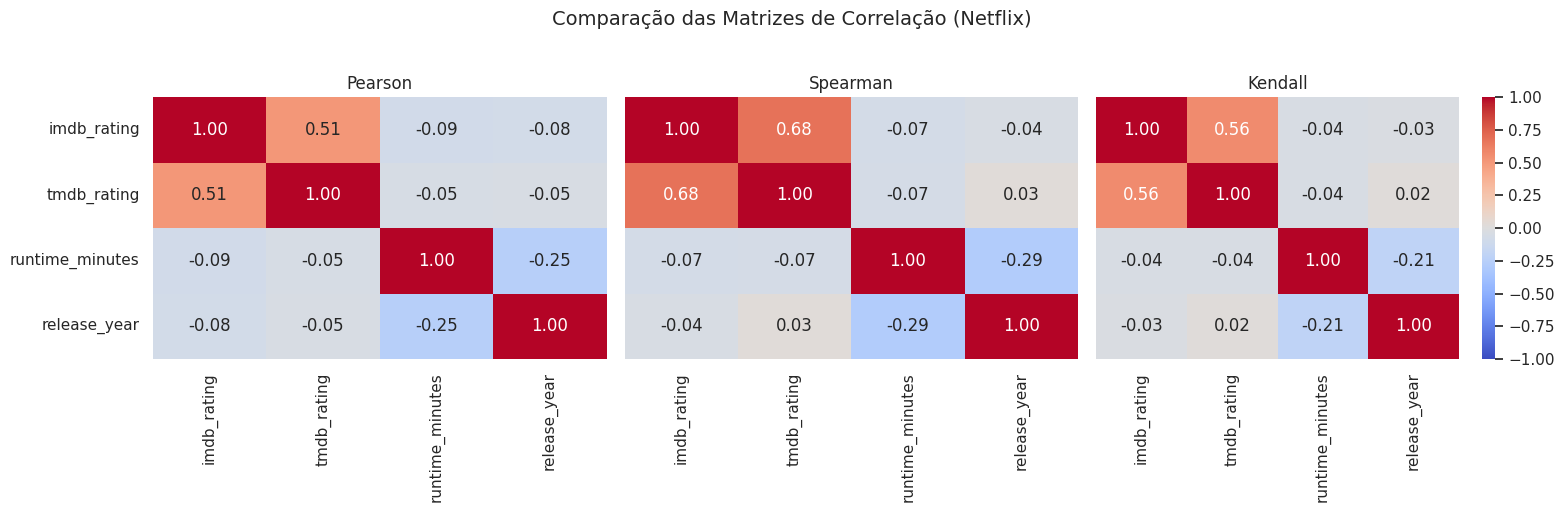

In [ ]:
VARS_QUANT = [col for col in ["imdb_rating", "tmdb_rating", "runtime_minutes", "popularity", "release_year"] if col in df.columns]

corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Pearson", fontsize=12)

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1], cbar=False)
ax[1].set_title("Spearman", fontsize=12)

sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2], cbar=True)
ax[2].set_title("Kendall", fontsize=12)

fig.suptitle("Comparação das Matrizes de Correlação (Netflix)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

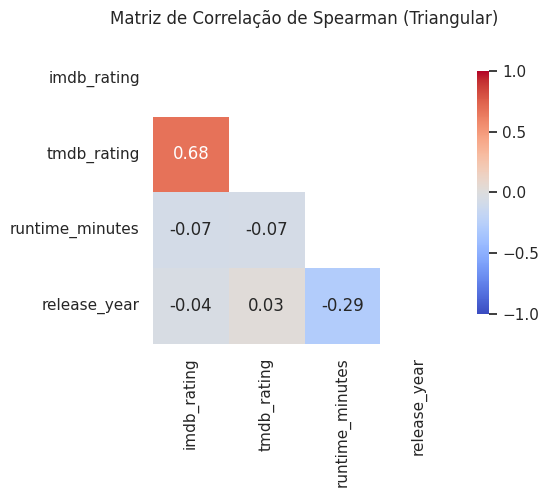

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(6, 5))

sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de Correlação de Spearman (Triangular)", fontsize=12, pad=12)
plt.grid(False)

plt.tight_layout()
plt.show()

### Discussão: Divergência entre Pearson e Spearman

Ao comparar as matrizes de correlação, destaca-se uma diferença no comportamento do par **`imdb_rating` e `tmdb_rating`**:

1. **`imdb_rating` vs `tmdb_rating`:**
   - **Pearson:** aproximadamente $0.51$.
   - **Spearman:** aproximadamente $0.68$.
   - **Interpretação:** a associação baseada em postos é mais forte do que a associação linear. Isso **sugere** que a relação pode não ser perfeitamente linear e/ou que outliers e assimetrias influenciam o coeficiente de Pearson. A diferença entre os coeficientes, sozinha, não prova não-linearidade.

2. **Demais pares (`runtime_minutes` e `release_year`):**
   - Para os demais cruzamentos, Pearson e Spearman permanecem próximos e, em geral, com magnitudes menores.

> **Conclusão:** Como as distribuições apresentam forte não-normalidade e outliers, o coeficiente de **Spearman** é uma escolha robusta para resumir associações monotônicas neste contexto, sempre lembrando que correlação não implica causalidade.

#### Dispersão (*Scatter Plot*) entre duas variáveis quantitativas

No dataset da **Netflix**, selecionamos o par **`imdb_rating` x `tmdb_rating`** orientados pelos resultados da matriz de correlação de Spearman, onde este par apresentou o maior coeficiente de associação do acervo ($r_s = 0.68$).

Diferente de contextos clínicos (onde existem relações fisiológicas diretas entre variáveis como idade e frequência cardíaca), na inteligência de conteúdo a estatística guia nossa escolha para verificar visualmente o grau de convergência e dispersão entre a avaliação dos usuários em duas plataformas distintas.

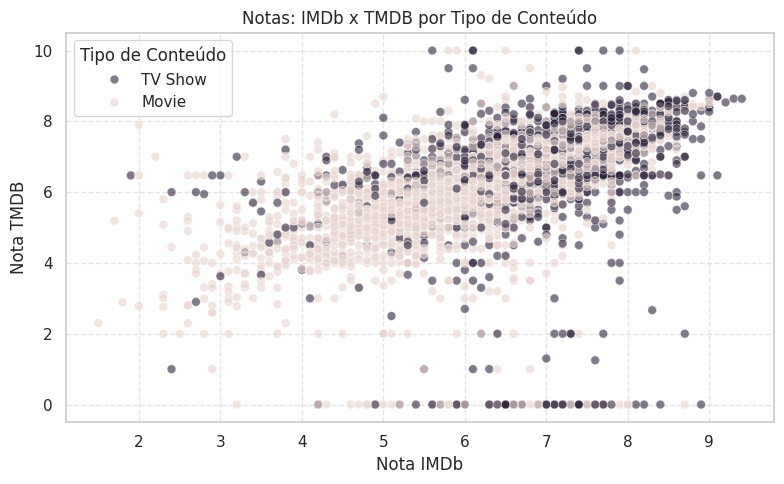

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="imdb_rating",
    y="tmdb_rating",
    hue="type",
    palette={"Movie": COR_CONTEXTO, "TV Show": COR_DESTAQUE},
    alpha=0.6,
    s=40
)

plt.title("Notas: IMDb x TMDB por Tipo de Conteúdo", fontsize=12)
plt.xlabel("Nota IMDb")
plt.ylabel("Nota TMDB")
plt.legend(title="Tipo de Conteúdo")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Discussão: Dispersão e Sobreposição de Classes

Ao analisar o gráfico de dispersão adaptado para o catálogo da Netflix (**`imdb_rating` x `tmdb_rating`** com separação por **`type`**):

1. **Tendência Visível:**
   - Observa-se uma **tendência positiva clara e ascendente**: conforme a nota no IMDb aumenta, a nota no TMDB também tende a subir. Isso reflete visualmente a correlação de Spearman de $0.68$ identificada na matriz, mostrando forte convergência na percepção de qualidade entre os usuários de ambas as plataformas.

2. **Comportamento das Classes (*Movie* vs. *TV Show*):**
   - As duas classes estão **bastante misturadas** ao longo de quase toda a faixa de notas, o que indica que tanto filmes quanto séries compartilham padrões semelhantes de distribuição de avaliações.
   - No entanto, nota-se uma leve diferença na densidade: a classe em destaque (**`TV Show`**) possui uma presença proporcionalmente mais concentrada na região superior do gráfico (notas entre $7.0$ e $9.0$), enquanto os filmes (**`Movie`**) apresentam uma dispersão maior e mais estendida para a faixa de notas medianas e baixas.

> **Conclusão:** O gráfico confirma que o formato de mídia (*Movie* ou *TV Show*) não segrega o acervo em regiões isoladas de avaliação, mas demonstra que as séries tendem a manter uma nota média ligeiramente mais alta e consistente entre as duas bases de dados.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada, revisamos o **Teste t de Student** (para 2 grupos) e a **ANOVA** (para 3 ou mais grupos) como testes paramétricos para comparar uma variável quantitativa entre categorias. Como as distribuições analisadas apresentam desvios relevantes de normalidade e outliers, também aplicaremos alternativas não-paramétricas:

- **Mann-Whitney U:** alternativa baseada em postos para comparar 2 grupos (ex.: `type` → *Movie* vs. *TV Show*).
- **Kruskal-Wallis:** alternativa baseada em postos para comparar 3 ou mais grupos (ex.: `release_year_group`).

Calcularemos as duas abordagens para fins comparativos, priorizando a interpretação dos testes não-paramétricos neste dataset.

In [ ]:
resultados_comparacao = []

for col in VARS_QUANT:
    grupo_movie = df.loc[df["type"] == "Movie", col].dropna()
    grupo_tv = df.loc[df["type"] == "TV Show", col].dropna()

    stat_t, p_t = stats.ttest_ind(grupo_movie, grupo_tv, equal_var=False)

    stat_u, p_u = stats.mannwhitneyu(grupo_movie, grupo_tv)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
imdb_rating,0.0,0.0,True
tmdb_rating,0.0,0.0,True
runtime_minutes,0.0,0.0,True
release_year,0.0,0.0,True


### Discussão: Concordância entre Testes e Escolha de Prioridade

Analisando a tabela para `imdb_rating`, `tmdb_rating`, `runtime_minutes` e `release_year`:

1. **Concordância da decisão estatística:**
   - Teste t e Mann-Whitney retornaram `p < 0.05` em todas as variáveis analisadas, portanto concordam quanto à rejeição da hipótese de igualdade entre os grupos.
   - Valores exibidos como `0.0` são consequência do arredondamento para cinco casas decimais; não significam p-valor matematicamente igual a zero.

2. **Qual teste priorizar?**
   - Neste notebook, o **Mann-Whitney U** é priorizado por ser baseado em postos e menos sensível à não-normalidade e a valores extremos.

3. **Ressalva de interpretação:**
   - Significância estatística não informa, sozinha, o tamanho nem a relevância prática da diferença. Os boxplots e medidas descritivas devem ser observados em conjunto.

ANOVA          — imdb_rating por release_year_group: estatística=14.427, p-valor=9.7064e-12
Kruskal-Wallis — imdb_rating por release_year_group: estatística=51.629, p-valor=1.6489e-10


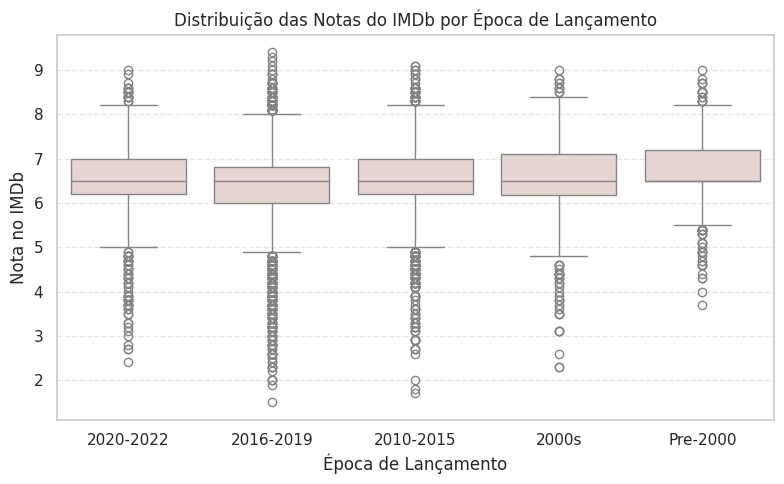

In [ ]:
grupos_ano = [grupo["imdb_rating"].dropna().values for _, grupo in df.groupby("release_year_group")]

stat_anova, p_anova = stats.f_oneway(*grupos_ano)

stat_kw, p_kw = stats.kruskal(*grupos_ano)

print(f"ANOVA          — imdb_rating por release_year_group: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — imdb_rating por release_year_group: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="release_year_group", y="imdb_rating", color=COR_CONTEXTO)

plt.title("Distribuição das Notas do IMDb por Época de Lançamento", fontsize=12)
plt.xlabel("Época de Lançamento")
plt.ylabel("Nota no IMDb")
plt.grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Discussão: Kruskal-Wallis vs. ANOVA (`imdb_rating` por `release_year_group`)

1. **Concordância dos testes:**
   - ANOVA (`p = 9.71 × 10⁻¹²`) e Kruskal-Wallis (`p = 1.65 × 10⁻¹⁰`) rejeitam a hipótese nula, indicando diferença entre pelo menos dois grupos de época de lançamento.

2. **Prioridade metodológica:**
   - O **Kruskal-Wallis** é usado como resultado principal porque trabalha com postos e é mais robusto frente à não-normalidade e aos outliers observados.

3. **Leitura prática do boxplot:**
   - O gráfico sugere diferenças de mediana e dispersão entre as épocas. Para identificar exatamente **quais pares** de grupos diferem, seria necessário um teste pós-hoc apropriado (por exemplo, Dunn com correção para múltiplas comparações).

#### Quantitativa x Qualitativa

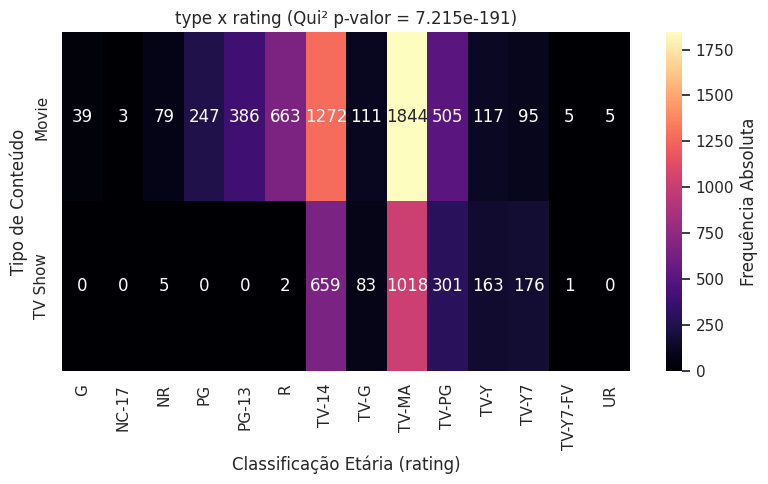

In [ ]:
contingencia_type_rating = pd.crosstab(df["type"], df["rating"])

chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_type_rating)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(contingencia_type_rating, annot=True, fmt="d", cmap="magma", ax=ax, cbar_kws={"label": "Frequência Absoluta"})

ax.set_title(f"type x rating (Qui² p-valor = {p_chi2:.4g})", fontsize=12)
ax.set_xlabel("Classificação Etária (rating)")
ax.set_ylabel("Tipo de Conteúdo")

plt.tight_layout()
plt.show()

### Discussão: Teste de Qui-Quadrado de Independência (`type` x `rating`)

1. **Interpretação do p-valor e Associação Estatística:**
   - O teste de Qui-Quadrado resultou em um **$p\text{-valor} = 7.215 \times 10^{-191}$**, um valor extraordinariamente inferior ao nível de significância padrão de $\alpha = 0.05$.
   - **Rejeita-se a hipótese nula ($H_0$):** Isso comprova que as variáveis `type` (*Movie* vs. *TV Show*) e `rating` (classificação etária) **não são independentes**. Existe uma associação estatisticamente significativa e muito forte entre o formato do conteúdo e a sua indicação etária.

2. **Análise do Padrão Visual no Heatmap:**
   - **Exclusividade de Sistemas de Classificação:** Classificações do cinema americano como *PG*, *PG-13*, *R* e *NC-17* aparecem quase exclusivamente na linha de **Movies** (com contagens zeradas ou irrelevantes em *TV Shows*).
   - **Predomínio do Padrão de TV:** Selos como *TV-14*, *TV-MA* e *TV-PG* concentram o maior volume absoluto em ambas as mídias, mas representam praticamente a totalidade dos títulos categorizados como **TV Show**.
   - **Público Adulto vs. Infanto-Juvenil:** A categoria *TV-MA* (destinada ao público adulto) lidera em volume bruto tanto para Filmes ($1844$) quanto para Séries ($1018$).

#### Avaliação de Fairness (Justiça Algorítmica e Viés de Catálogo)

Olhar o desbalanceamento da base inteira é apenas metade da história. No contexto de **Content Intelligence** e sistemas de recomendação da Netflix, a avaliação de **fairness** busca identificar se a distribuição do catálogo e a qualidade das avaliações se comportam de forma equitativa em diferentes subgrupos de atributos — como tipo de mídia (`type`), país de origem (`country`) ou maturidade do público (`rating`).

Se certos subgrupos (como conteúdos não-americanos ou gêneros específicos) apresentarem distribuições desproporcionais de notas ou volume reduzido, isso pode refletir um padrão real de mercado ou um **viés na amostragem e curadoria dos dados**. Mapear essas assimetrias é fundamental **antes** de avançar para a etapa de engenharia de recursos e modelagem preditiva.

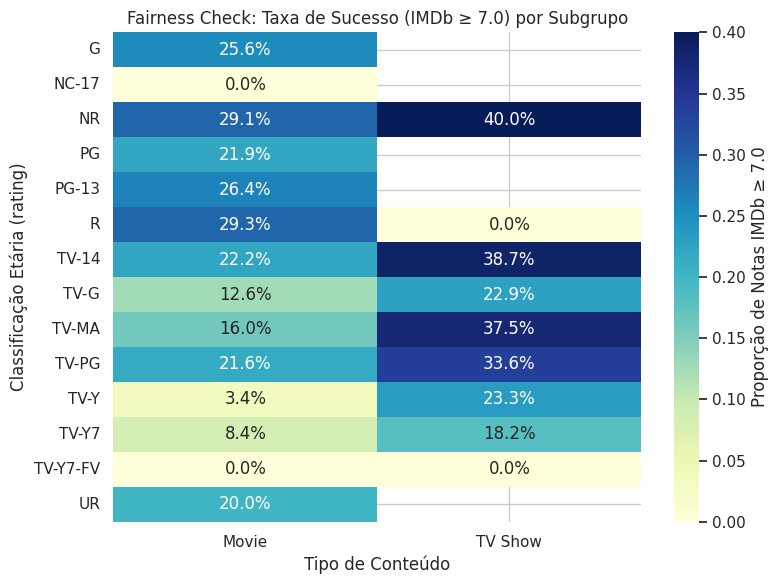

In [ ]:
df["alta_avaliacao"] = (df["imdb_rating"] >= 7.0).astype(int)

fairness_tab = pd.crosstab(
    df["rating"],
    df["type"],
    values=df["alta_avaliacao"],
    aggfunc="mean"
).round(3)

plt.figure(figsize=(8, 6))
sns.heatmap(fairness_tab, annot=True, cmap="YlGnBu", fmt=".1%", cbar_kws={"label": "Proporção de Notas IMDb ≥ 7.0"})

plt.title("Fairness Check: Taxa de Sucesso (IMDb ≥ 7.0) por Subgrupo", fontsize=12)
plt.xlabel("Tipo de Conteúdo")
plt.ylabel("Classificação Etária (rating)")

plt.tight_layout()
plt.show()

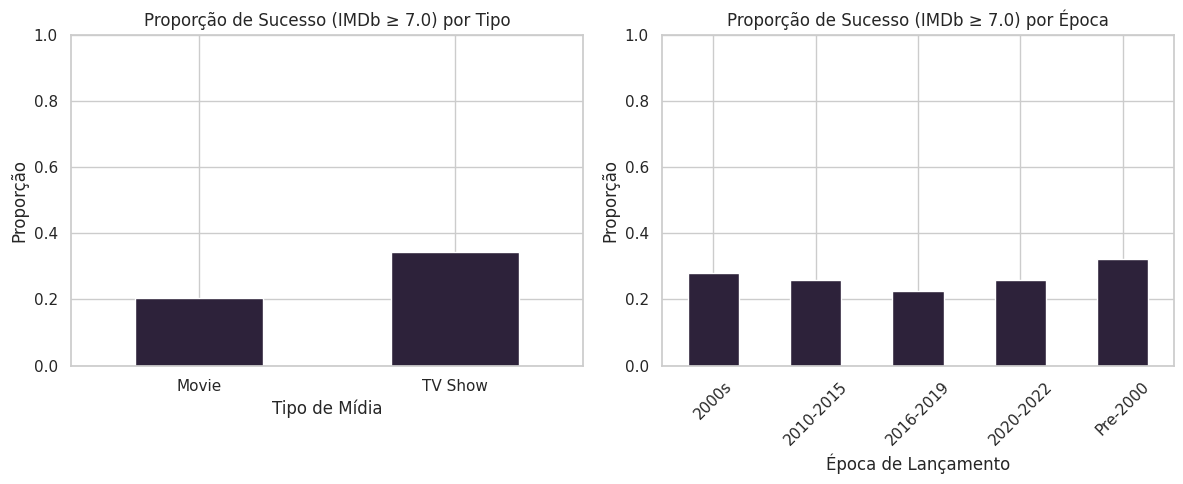

In [ ]:
df["alta_avaliacao"] = (df["imdb_rating"] >= 7.0).astype(int)

prop_por_tipo = pd.crosstab(df["type"], df["alta_avaliacao"], normalize="index").round(3)
prop_por_faixa_ano = pd.crosstab(df["release_year_group"], df["alta_avaliacao"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_tipo[1].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção de Sucesso (IMDb ≥ 7.0) por Tipo")
axes[0].set_ylabel("Proporção")
axes[0].set_xlabel("Tipo de Mídia")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa_ano[1].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção de Sucesso (IMDb ≥ 7.0) por Época")
axes[1].set_ylabel("Proporção")
axes[1].set_xlabel("Época de Lançamento")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Análise Quantitativa dos Gráficos de Fairness

Com base nos gráficos de barras:

1. **Disparidade por Tipo de Mídia (`type`):**
   - **Movie:** proporção aproximada de **20%** de títulos com $IMDb \ge 7.0$.
   - **TV Show:** proporção aproximada de **34%**.
   - **Diferença absoluta:** cerca de **14 pontos percentuais**.

2. **Disparidade por Época de Lançamento (`release_year_group`):**
   - **Pre-2000:** cerca de **32%**.
   - **2000s:** cerca de **28%**.
   - **2010-2015:** cerca de **26%**.
   - **2016-2019:** cerca de **22%**.
   - **2020-2022:** cerca de **26%**.

> **Síntese Metodológica:** Os gráficos demonstram **associações e diferenças de proporção**, mas não identificam a causa. Hipóteses como *survivorship bias*, seleção do catálogo, diferenças de público ou de processo de avaliação podem ser investigadas posteriormente, porém não podem ser confirmadas apenas por esta EDA. Além disso, como `imdb_rating` foi imputado pela mediana, essas proporções devem ser interpretadas com cautela.

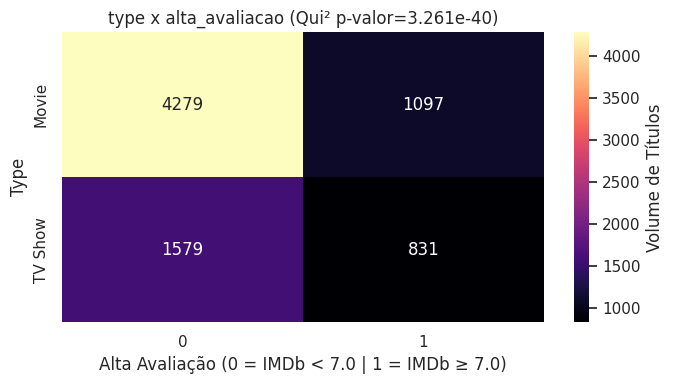

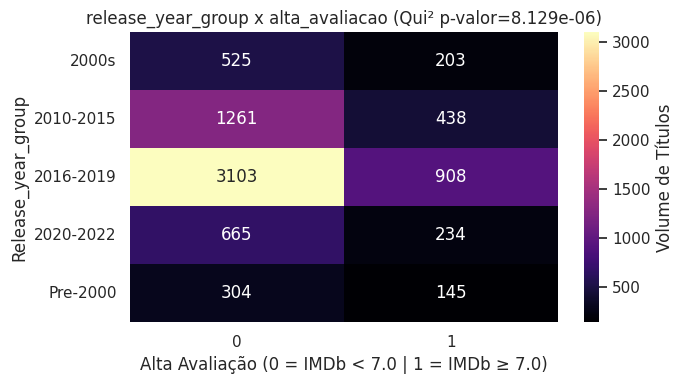

In [ ]:
for atributo in ["type", "release_year_group"]:
    contingencia = pd.crosstab(df[atributo], df["alta_avaliacao"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax, cbar_kws={"label": "Volume de Títulos"})

    ax.set_title(f"{atributo} x alta_avaliacao (Qui² p-valor={p_valor:.4g})", fontsize=12)
    ax.set_xlabel("Alta Avaliação (0 = IMDb < 7.0 | 1 = IMDb ≥ 7.0)")
    ax.set_ylabel(atributo.capitalize())

    plt.tight_layout()
    plt.show()

### Discussão: Associação Estatística ($\chi^2$) vs. Causalidade na Avaliação de Fairness

1. **Associação estatística:**
   - **`type` x `alta_avaliacao`:** o p-valor muito baixo indica associação estatisticamente significativa entre tipo de conteúdo e o indicador $IMDb \ge 7.0$.
   - **`release_year_group` x `alta_avaliacao`:** o teste também indica associação estatisticamente significativa entre época de lançamento e alta avaliação.

2. **Associação não é causalidade:**
   - O Qui-Quadrado mostra que as proporções diferem entre subgrupos, mas não explica por que isso ocorre.
   - A maior proporção observada em séries e em títulos mais antigos pode ser compatível com diferentes hipóteses (perfil de público, seleção do catálogo, disponibilidade de avaliações, sobrevivência de títulos antigos etc.), mas o dataset não permite escolher uma causa única.

> **Conclusão para a checagem de subgrupos:** O teste cumpre o papel de sinalizar assimetrias que merecem investigação. Antes de usar essas variáveis em modelagem, é importante evitar interpretar essas associações como regras causais de desempenho.

#### Outliers bivariados

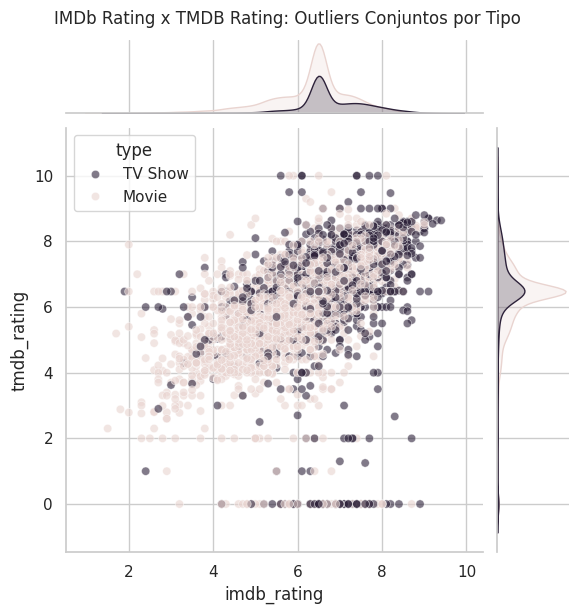

In [ ]:
g = sns.jointplot(
    data=df,
    x="imdb_rating",
    y="tmdb_rating",
    hue="type",
    palette={"Movie": COR_CONTEXTO, "TV Show": COR_DESTAQUE},
    alpha=0.6,
    height=6
)

g.fig.suptitle("IMDb Rating x TMDB Rating: Outliers Conjuntos por Tipo", y=1.02, fontsize=12)

plt.show()

### Discussão: Outliers Bivariados vs. Outliers Univariados (`imdb_rating` x `tmdb_rating`)

1. **Combinações incomuns:**
   - Existem pontos que podem parecer normais quando cada variável é analisada isoladamente, mas se destacam quando IMDb e TMDB são observados em conjunto.
   - Exemplos visuais incluem notas muito baixas no TMDB acompanhadas de notas medianas/altas no IMDb e casos de grande discordância entre as plataformas.

2. **Por que a análise univariada não captura esses casos?**
   - Uma nota individual pode estar dentro da faixa válida de cada plataforma, mas a **combinação** pode ser rara em relação ao padrão geral de associação positiva.

3. **Impacto para a modelagem:**
   - Esses registros devem ser **investigados**, não removidos automaticamente. A divergência pode representar poucos votos, diferenças reais entre públicos/plataformas, ausência codificada de forma inadequada ou erro de coleta. A confirmação exige verificar campos auxiliares (como número de votos) e, se possível, a fonte original.

#### Análise Multivariada

##### Matriz de Correlação

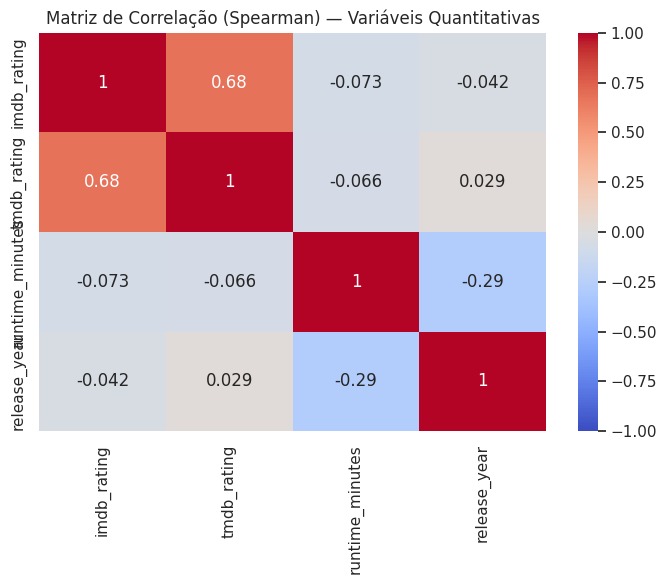

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


### Discussão: Interpretação da Matriz de Correlação (Spearman)

Analisando os coeficientes para `imdb_rating`, `tmdb_rating`, `runtime_minutes` e `release_year`:

1. **Força das associações:**
   - **`imdb_rating` x `tmdb_rating` ($r_s pprox 0.68$):** associação monotônica positiva de magnitude moderada a forte.
   - **`runtime_minutes` x `release_year` ($r_s pprox -0.29$):** associação negativa fraca.
   - **Demais cruzamentos:** associações fracas ou próximas de zero, indicando pouca relação monotônica direta.

2. **Redundância / multicolinearidade:**
   - A correlação de $0.68$ mostra informação compartilhada relevante entre IMDb e TMDB, mas **não é suficiente, sozinha, para decidir excluir uma variável**.
   - Em uma etapa de modelagem, a decisão deve considerar objetivo, algoritmo, interpretabilidade e diagnósticos específicos de colinearidade (por exemplo, VIF em modelos lineares), em vez de aplicar um limiar rígido de correlação como regra universal.

##### Correlograma

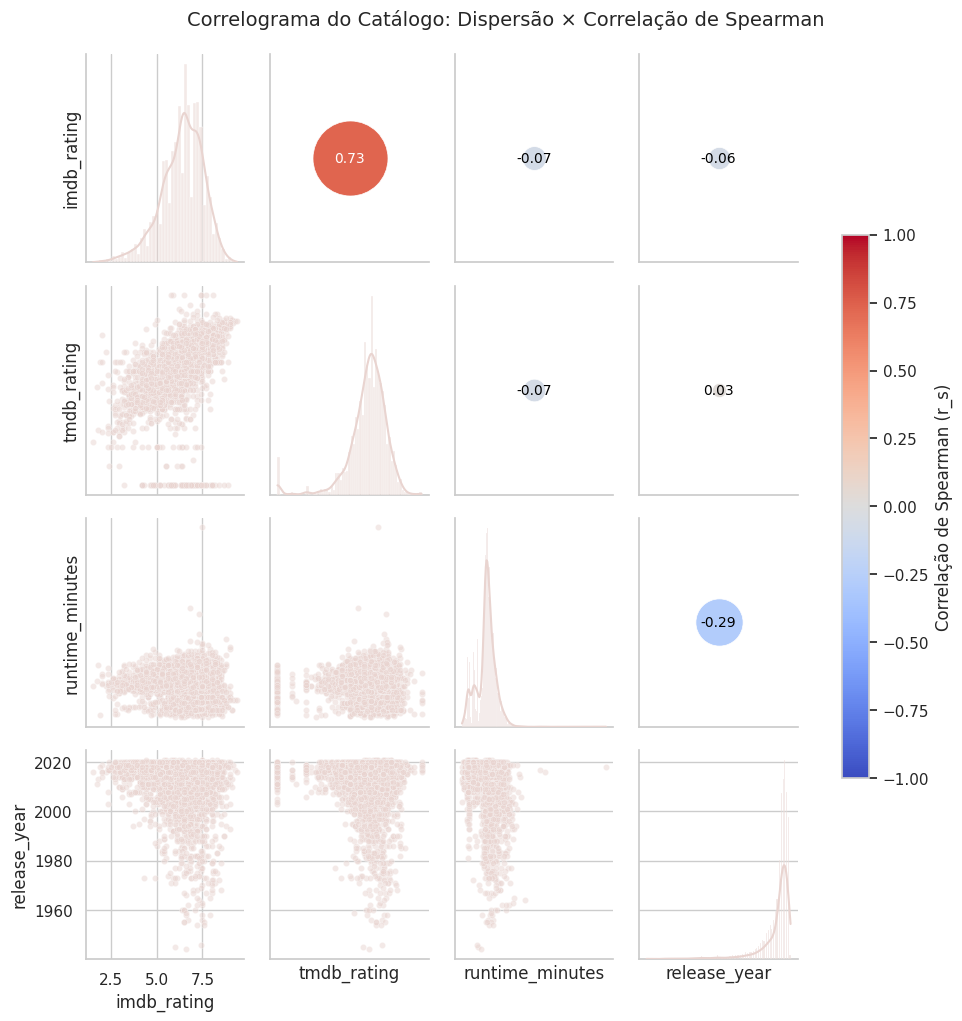

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao_spearman(x, y, **kwargs):
    mask = ~(np.isnan(x) | np.isnan(y))
    x_clean, y_clean = x[mask], y[mask]

    if len(x_clean) < 2:
        return

    r, _ = stats.spearmanr(x_clean, y_clean)

    if np.isnan(r):
        return

    ax = plt.gca()

    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5
    )

    ax.annotate(
        f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
        ha="center", va="center", fontsize=10,
        color="white" if abs(r) > 0.5 else "black"
    )
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

vars_validas = [col for col in VARS_QUANT if df[col].dropna().nunique() > 1]

g = sns.PairGrid(df[vars_validas].dropna(), diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_CONTEXTO, alpha=0.5, s=20)
g.map_diag(sns.histplot, color=COR_CONTEXTO, kde=True)
g.map_upper(circulo_correlacao_spearman)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (r_s)")

g.fig.suptitle("Correlograma do Catálogo: Dispersão × Correlação de Spearman", y=1.02, fontsize=14)
plt.show()

### Fechamento da Atividade — EDA Hands-on

---

### 1. Principais Conclusões (Síntese da EDA)

- **Estrutura e qualidade dos dados:** O dataset possui **7.786 registros e 40 colunas**, sem linhas duplicadas. Há um volume relevante de ausências, principalmente nas variáveis enriquecidas por IMDb/TMDB, compatível com limitações do processo de *matching* entre fontes.
- **Distribuições e normalidade:** As variáveis quantitativas apresentam assimetrias, caudas pesadas e outliers. O Shapiro-Wilk rejeitou normalidade nas variáveis testadas; como a amostra é grande (e em alguns casos supera 5.000 observações), a interpretação foi feita em conjunto com histogramas, QQ-Plots, assimetria e curtose.
- **Tratamento de ausentes:** Para `imdb_rating` e `tmdb_rating`, foi utilizada imputação pela mediana para evitar grande perda de registros. A comparação antes/depois mostrou que essa decisão concentra observações em torno da mediana, uma limitação que deve ser considerada em análises futuras.
- **Outliers:** A regra do IQR identificou muitos valores extremos em `imdb_votes`, `tmdb_popularity`, `country_count`, `release_year/content_age` e `runtime_minutes`. A maior parte foi mantida por ser plausível no domínio, evitando remoção automática de títulos legítimos.
- **Análises bivariadas:** Os testes Mann-Whitney U e Kruskal-Wallis apontaram diferenças estatisticamente significativas entre grupos. O Qui-Quadrado também identificou associações entre variáveis categóricas/subgrupos. Esses resultados indicam associação, não causalidade.
- **Correlação:** A principal associação monotônica observada foi entre `imdb_rating` e `tmdb_rating` ($r_s pprox 0.68$). A correlação é relevante, mas não justifica excluir automaticamente uma das variáveis.
- **Outliers bivariados:** O cruzamento IMDb × TMDB revelou combinações incomuns que não seriam evidentes em análises univariadas. Esses registros devem ser investigados antes de qualquer decisão de remoção.

---

### 2. Declaração de Uso de Inteligência Artificial

- **Ferramentas utilizadas:** IA Generativa (Gemini, em etapas anteriores registradas no notebook, e ChatGPT na revisão final).
- **Escopo da aplicação:**
  1. Adaptação de exemplos e códigos da atividade-base para o dataset de catálogo da Netflix.
  2. Apoio na revisão de sintaxe, visualizações e testes estatísticos com `pandas`, `seaborn`, `matplotlib` e `scipy.stats`.
  3. Revisão das interpretações para diferenciar associação de causalidade e explicitar limitações de imputação, normalidade e outliers.
  4. Correção de trechos remanescentes do exemplo clínico original, mantendo a estrutura e o estilo da atividade proposta pela professora.
- **Avaliação crítica do uso da IA:** As sugestões foram revisadas e adaptadas ao dataset. Foram mantidas as análises coerentes com os resultados apresentados, modificadas afirmações excessivamente causais e rejeitadas decisões automáticas de exclusão de variáveis ou outliers sem evidência suficiente.